# 08 - Feature relationships and feature selection

Three parts:
1. **Load and build features** - read the cleaned, merged table from `07_joined_table.ipynb` and turn its columns into model features
2. **How features relate** - correlations, highly correlated pairs, and how each feature relates to price on its own
3. **Feature selection** - VIF, forward and backward selection, RFECV, lasso, interaction terms, and outliers / high leverage points

All cleaning (time zones, venue locations, duplicates, US only, 3+ listings, extreme prices, non-concerts) was done in notebooks 06 and 07, so this notebook only builds features and selects them.

**Input:** `../data/joined_table.csv`
**Output:** `../data/model_table.csv` (one row per show, all candidate features, target, and a `split` column for train/test)

## 0. Setup

In [48]:
# imports
import numpy as np
import pandas as pd
import seaborn as sns
import matplotlib.pyplot as plt
import statsmodels.api as sm
import statsmodels.formula.api as smf
from statsmodels.stats.outliers_influence import variance_inflation_factor, OLSInfluence

from sklearn.linear_model import LinearRegression, LassoCV, lasso_path
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import make_column_transformer
from sklearn.pipeline import make_pipeline
from sklearn.feature_selection import SequentialFeatureSelector, RFECV
from sklearn.model_selection import train_test_split, KFold, cross_val_score
from sklearn.metrics import root_mean_squared_error

In [49]:
# defining data directory to load in data
DATA_DIR = "../data/"

# setting random state for train/test split
RANDOM_STATE = 6021

# Part 1 - Loading in data and building features

## 1.1 Load the merged table

In [50]:
# loading in the merged table from 07
# having it parse the date columns so they are formatted correctly for building indicator variables
df = pd.read_csv(DATA_DIR + "joined_table.csv", parse_dates=["start_utc", "start_local", "snapshot_date"])

# looking at basic info to make sure it lines up with earlier results
print("shows:", len(df))
print("artists:", df["artist_key"].nunique())
print("venues:", df["venue_key"].nunique())
print("first show:", df["start_local"].min())
print("last show:", df["start_local"].max())
print(df.head(3))

shows: 15084
artists: 2872
venues: 2033
first show: 2026-07-27 18:30:00
last show: 2026-11-08 18:30:00
            artist_key                                          venue_key  \
0           houndmouth  frederik meijer gardens amphitheater|grand rapids   
1  5 seconds of summer                  riverbend music center|cincinnati   
2                poppy                                      admiral|omaha   

                   event_id                 name          artist_name  \
0  69d8115d8f7499b0f6720c9c           Houndmouth           Houndmouth   
1  68fa3930a768106fd704bfa3  5 Seconds of Summer  5 Seconds of Summer   
2  69950bd9ee953753416d5dcd                Poppy                Poppy   

                                  venue  start_utc         start_local  \
0  Frederik Meijer Gardens Amphitheater 2026-07-28 2026-07-27 20:00:00   
1                Riverbend Music Center 2026-07-28 2026-07-27 20:00:00   
2                           The Admiral 2026-07-28 2026-07-27 19:00:00   

In [51]:
# quick checks that 06 and 07 did what they were supposed to
# each of these counts the rows that break the rules enforced in 06 and 07
print("repeated event_id:", df["event_id"].duplicated().sum())
print("shows outside the US:", (df["is_us"] == False).sum())
print("shows with fewer than 3 listings:", (df["listings"] < 3).sum())
print("shows priced over $2,000:", (df["price_median"] > 2000).sum())
print("shows with no Last.fm popularity:", df["listeners"].isna().sum())

repeated event_id: 0
shows outside the US: 0
shows with fewer than 3 listings: 0
shows priced over $2,000: 0
shows with no Last.fm popularity: 0


In [52]:
# calculating the percent of rows missing in each column
missing = df.isna().mean() * 100
missing = missing[missing > 0].sort_values(ascending=False)
missing.round(1)

year_formed           88.4
years_active          88.4
artist_country        86.8
median_income         21.2
lat                   20.9
lon                   20.9
sg_venue_score        20.9
sg_upcoming_events    20.9
top_tag                9.4
tags                   9.4
dtype: float64

**Columns we don't use as features:**
- `artist_country`, `year_formed`, `years_active`: 86-88% missing.
- `venue_tier` (from venue capacity): "unknown" for most shows.
- `max_listings`, `n_priced_days`, `median_max_listings`: computed over **every** day Gametime tracked the show, including days after the snapshot (about 14 days before the show) that we predict from. Using them would let information from the future into the model. `venue_listings` (07) is the venue-size stand-in that only uses snapshot-day listings.
- `show_hour`: replaced by the 3-level `time_of_day` below.

## 1.2 Creating Genre Feature: collapse the Last.fm tags into 11 groups
`top_tag` has hundreds of different values, and some aren't genres at all. Instead we read each artist's tags in order and take the first one that matches a genre keyword. The genres are checked in the order written, so more specific ones (latin, electronic, hip-hop) are matched before broad ones (pop, rock). Artists with no tags are "unknown". Artists that match nothing are "other".

In [53]:
# keywords for each genre group
# the groups are checked top to bottom, so the more specific ones (latin, electronic) come before broad ones (pop, rock)
GENRES = {
    "classical/soundtrack": ["classical", "orchestra", "symphon", "soundtrack", "opera", "score", "video game"],
    "latin": ["latin", "reggaeton", "corridos", "mariachi", "cumbia", "mexic", "salsa", "bachata", "flamenco", "banda", "tejano"],
    "electronic": ["electronic", "house", "techno", "dubstep", "trance", "edm", "dance", "drum and bass", "dnb",
                   "trip-hop", "synthwave", "chillwave", "electro", "idm", "breakcore", "bass"],
    "hip-hop/rap": ["hip-hop", "hip hop", "rap", "trap", "drill", "grime"],
    "r&b/soul": ["rnb", "r&b", "soul", "funk", "motown", "gospel"],
    "country": ["country", "bluegrass", "americana", "honky", "red dirt", "outlaw"],
    "jazz/blues": ["jazz", "blues", "swing", "bebop", "fusion"],
    "metal/punk": ["metal", "deathcore", "grindcore", "punk", "emo", "hardcore", "screamo", "ska"],
    "folk": ["folk", "singer-songwriter", "acoustic", "celtic", "irish"],
    "pop": ["pop", "female vocalists", "boy band", "girl group", "disco"],
    "rock/indie": ["rock", "indie", "alternative", "grunge", "new wave", "shoegaze", "psychedelic", "jam", "garage"],
}

# applying our genres dictionary to get a genre for the artists
def tags_to_genre(tags):
    # no tags at all
    if pd.isna(tags):
        return "unknown"
    # tags are split by ";" and the first one is the most used tag on Last.fm
    for tag in tags.lower().split(";"):
        tag = tag.strip()
        for genre in GENRES:
            for word in GENRES[genre]:
                if word in tag:
                    return genre
    # there were tags but none of them matched a genre keyword
    return "other"

# looking at the popularity of the different genres
df["genre"] = df["tags"].apply(tags_to_genre)
df["genre"].value_counts()

genre
rock/indie              3206
country                 2094
metal/punk              1428
unknown                 1422
pop                     1328
folk                    1032
r&b/soul                 855
electronic               848
jazz/blues               841
hip-hop/rap              834
latin                    538
classical/soundtrack     457
other                    201
Name: count, dtype: int64

In [54]:
# checking 10 random artists to see their tags compared to the genre they were assigned
artists_only = df.drop_duplicates("artist_key")
artists_only[["artist_name", "tags", "genre"]].sample(10, random_state=1)
# this looks good so the genre feature is accurate

,artist_name,tags,genre
8462,Infinity Song,soft rock; soul; rnb; indie pop; usa,rock/indie
7697,La Mafia,tejano; la mafia-los hits; cumbia texana; span...,latin
11139,Josiah and the Bonnevilles,alt-country; folk; indie; americana; all,country
1293,Broadway Rave,NaN,unknown
9184,Los Hermanos Rosario,merengue; dominican republic; latin; dance; salsa,latin
1896,Goose,electronic; electro; new rave; belgian; belgium,electronic
411,Tedeschi Trucks Band,blues rock; female vocalists; blues; rock; jam...,jazz/blues
1218,United We Dance,NaN,unknown
4383,Black Veil Brides,post-hardcore; screamo; rock; emo; gothic glam,metal/punk
6373,Emerson,metalcore; hardcore; melodic hardcore; metal; ...,metal/punk


## 1.3 Build the features
Every feature below is known on the snapshot day. Skewed counts are logged, so a coefficient means "the effect of a doubling" instead of "the effect of one more", and a few huge values don't dominate.

| Feature | Type | What it is |
|---|---|---|
| `log_listings` | numeric | log of the number of resale listings on the snapshot day (supply / market size) |
| `log_venue_listings` | numeric | log of the venue's typical (median) listings on the snapshot day across all its shows: a venue-size stand-in |
| `log_listeners` | numeric | log of Last.fm listeners (artist popularity) |
| `log_plays_per_listener` | numeric | log of Last.fm plays per listener (how devoted the fans are) |
| `log_artist_shows` | numeric | log of the artist's number of shows in the data (tour size) |
| `days_to_show` | numeric | days between the snapshot and the show (10-18, almost always 14) |
| `sg_venue_score` | numeric | SeatGeek's venue score (0-1). SeatGeek doesn't document how it is computed; we read it as venue popularity |
| `log_sg_upcoming_events` | numeric | log of the venue's upcoming events on SeatGeek (how busy the venue is) |
| `log_median_income` | numeric | log of the venue county's median household income (Census) |
| `genre` | categorical | 13 groups from 1.2 (11 genres, "other", "unknown") |
| `region` | categorical | Census region from the venue's state (Northeast, Midwest, South, West) |
| `weekday` | categorical | day of the show (local time) |
| `time_of_day` | categorical | early (before 5 pm) / evening (5-8 pm) / late (9 pm or later) start, local time |
| `month` | categorical | month of the show |
| `is_weekend` | binary | Friday or Saturday show |
| `is_vegas` | binary | venue in Las Vegas (many residencies, high prices) |
| `on_tour` | binary | Last.fm says the artist is touring |
| `sg_unmatched` | binary | venue not found on SeatGeek, so its SeatGeek and income values are filled in (3.1) |

The **target** is `log_price` = log of the median resale price. Prices are very right-skewed in dollars and close to symmetric on the log scale.

In [55]:
# creating region dictionary for each state
CENSUS_REGION = {
    "Northeast": ["CT", "ME", "MA", "NH", "RI", "VT", "NJ", "NY", "PA"],
    "Midwest":   ["IL", "IN", "MI", "OH", "WI", "IA", "KS", "MN", "MO", "NE", "ND", "SD"],
    "South":     ["DE", "DC", "FL", "GA", "MD", "NC", "SC", "VA", "WV", "AL", "KY", "MS", "TN", "AR", "LA", "OK", "TX"],
    "West":      ["AZ", "CO", "ID", "MT", "NV", "NM", "UT", "WY", "AK", "CA", "HI", "OR", "WA"],
}
# applying region dictionary to get the region feature
df["region"] = "unknown"
for region in CENSUS_REGION:
    df.loc[df["state"].isin(CENSUS_REGION[region]), "region"] = region

# defining and computing out target/outcome: log of the median resale price
df["log_price"] = np.log(df["price_median"])

# taking the log of numeric features 
df["log_listings"] = np.log(df["listings"])
df["log_venue_listings"] = np.log(df["venue_listings"])
df["log_listeners"] = np.log(df["listeners"])
df["log_plays_per_listener"] = np.log(df["plays_per_listener"])
df["log_artist_shows"] = np.log(df["n_shows"])
df["log_median_income"] = np.log(df["median_income"])
# log1p = log(1 + x) since some venues have 0 upcoming events
df["log_sg_upcoming_events"] = np.log1p(df["sg_upcoming_events"])

# creating month as a categorical variable instead of a number
df["month"] = df["month"].astype(str)

# creating time_of_day categorical indicator for when the show was
hour = df["start_local"].dt.hour
df["time_of_day"] = "late (9pm or later)"
df.loc[(hour >= 6) & (hour <= 16), "time_of_day"] = "early (before 5pm)"
df.loc[(hour >= 17) & (hour <= 20), "time_of_day"] = "evening (5-8pm)"
# looking at these groupings
df["time_of_day"].value_counts()

# creating binary features
df["is_weekend"] = df["is_weekend"].astype(int)
df["is_vegas"] = (df["city"].str.lower() == "las vegas").astype(int)
df["on_tour"] = df["on_tour"].astype(int)
# 1 if the venue wasn't found on SeatGeek
df["sg_unmatched"] = df["sg_venue_score"].isna().astype(int)



In [56]:
# defining the different types of variables we now want to test
NUMERIC = ["log_listings", "log_venue_listings", "log_listeners", "log_plays_per_listener", "log_artist_shows",
           "days_to_show", "sg_venue_score", "log_sg_upcoming_events", "log_median_income"]
CATEGORICAL = ["genre", "region", "weekday", "time_of_day", "month"]
BINARY = ["is_weekend", "is_vegas", "on_tour", "sg_unmatched"]
CANDIDATES = NUMERIC + CATEGORICAL + BINARY
TARGET = "log_price"

# summary stats for numeric features and target
df[NUMERIC + [TARGET]].describe().T.round(2)

,count,mean,std,min,25%,50%,75%,max
log_listings,15084.0,2.74,1.14,1.10,1.79,2.56,3.69,6.04
log_venue_listings,15084.0,2.59,1.28,0.00,1.61,2.53,3.65,5.95
log_listeners,15084.0,11.81,3.13,0.00,11.11,12.60,13.76,15.77
log_plays_per_listener,15084.0,2.85,0.85,0.00,2.33,2.80,3.38,7.54
log_artist_shows,15084.0,2.79,0.82,0.00,2.40,2.94,3.37,4.62
days_to_show,15084.0,13.99,0.97,10.00,14.00,14.00,14.00,18.00
sg_venue_score,11933.0,0.59,0.17,0.00,0.49,0.59,0.70,1.00
log_sg_upcoming_events,11933.0,2.70,1.49,0.00,1.61,2.94,3.87,6.24
log_median_income,11886.0,11.32,0.23,10.53,11.17,11.31,11.46,11.98
log_price,15084.0,4.81,0.62,2.30,4.41,4.71,5.11,7.58


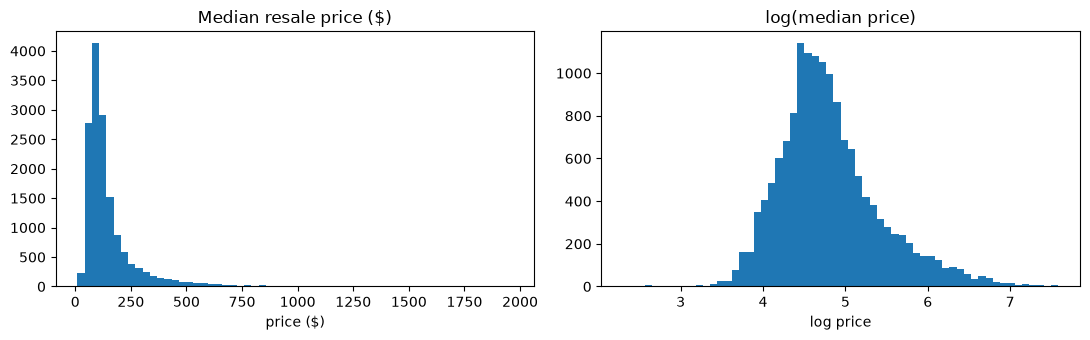

skew in dollars: 4.38
skew of the log: 0.87


In [57]:
# histograms of the price in dollars and the log price
fig, axes = plt.subplots(1, 2, figsize=(11, 3.5))
axes[0].hist(df["price_median"], bins=60)
axes[0].set(title="Median resale price ($)", xlabel="price ($)")
axes[1].hist(df["log_price"], bins=60)
axes[1].set(title="log(median price)", xlabel="log price")
plt.tight_layout()
plt.show()

print("skew in dollars:", round(df["price_median"].skew(), 2))
print("skew of the log:", round(df["log_price"].skew(), 2))

# Part 2 - How the features relate to each other and to price
Two questions: (1) which features move together because strongly related features make coefficients unstable and hard to read? (2) How much does each feature explain about price on its own?

## 2.1 Correlation matrix
Pearson correlations between the numeric features, the binary features (0/1) and the target. Each pair uses the rows where both values are present.

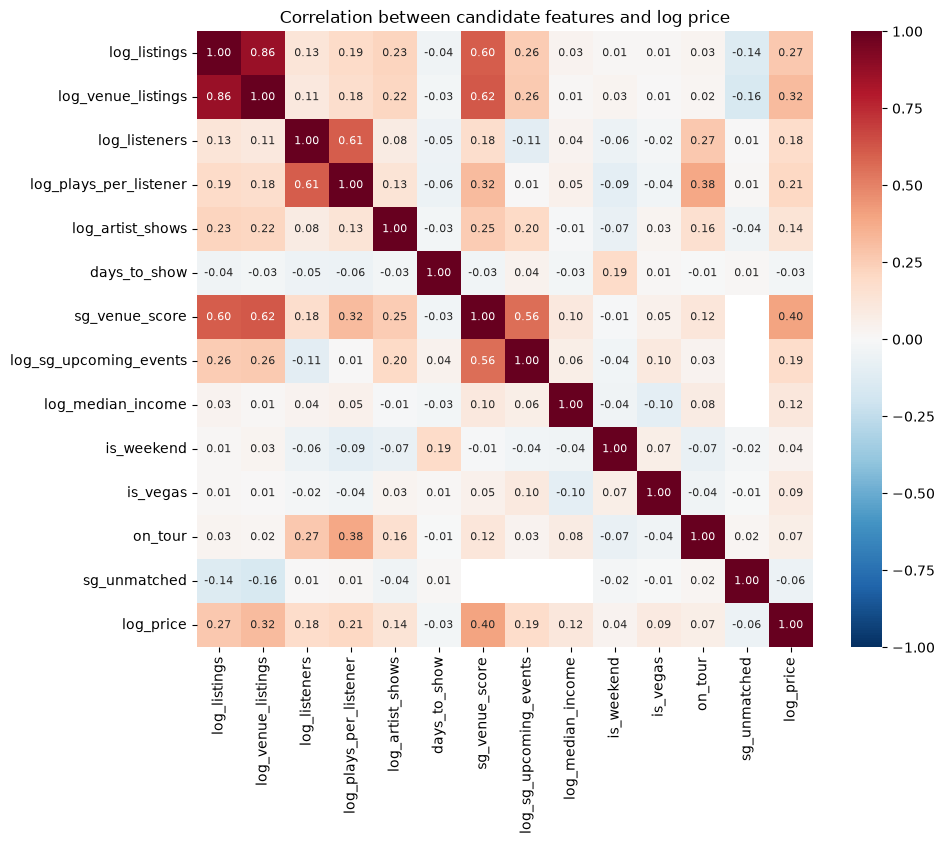

In [58]:
# correlation matrix (heatmap code similar to the class notebooks)
corr = df[NUMERIC + BINARY + [TARGET]].corr()

fig, ax = plt.subplots(figsize=(10, 8))
sns.heatmap(corr, annot=True, fmt=".2f", cmap="RdBu_r", vmin=-1, vmax=1, square=True, annot_kws={"size": 8}, ax=ax)
ax.set_title("Correlation between candidate features and log price")
plt.show()

## 2.2 Highly correlated pairs
Every pair of features with |r| above 0.5. These are the pairs to watch in the VIF (3.2).

In [59]:
# going through every pair of features once and saving the correlation
features = NUMERIC + BINARY
rows = []
for i in range(len(features)):
    for j in range(i + 1, len(features)):
        rows.append({"feature 1": features[i], "feature 2": features[j], "r": corr.loc[features[i], features[j]]})
pairs = pd.DataFrame(rows)

# keeping only the pairs with |r| above 0.5
high_pairs = pairs[pairs["r"].abs() > 0.5].sort_values("r", ascending=False)
display(high_pairs.round(3))

,feature 1,feature 2,r
0,log_listings,log_venue_listings,0.863
16,log_venue_listings,sg_venue_score,0.622
23,log_listeners,log_plays_per_listener,0.608
5,log_listings,sg_venue_score,0.602
57,sg_venue_score,log_sg_upcoming_events,0.559


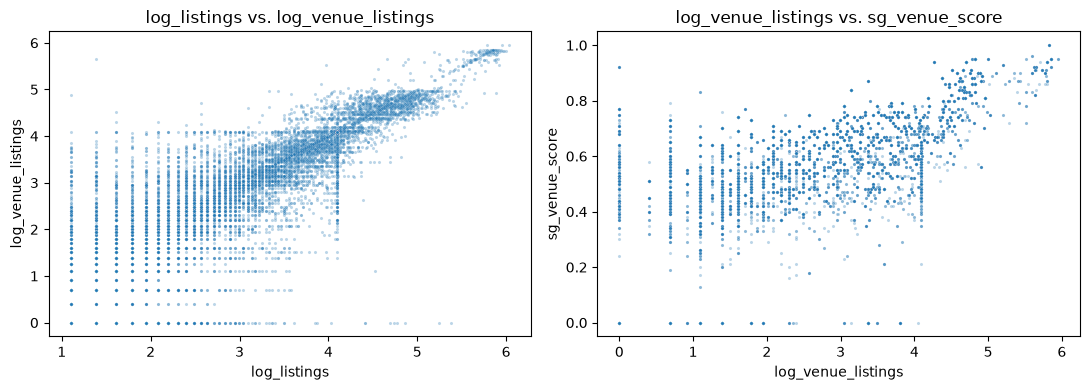

In [60]:
# scatter plots of the two most correlated pairs (like temp vs. atemp in class)
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
sns.scatterplot(data=df, x="log_listings", y="log_venue_listings", s=5, alpha=0.3, ax=axes[0])
axes[0].set_title("log_listings vs. log_venue_listings")
sns.scatterplot(data=df, x="log_venue_listings", y="sg_venue_score", s=5, alpha=0.3, ax=axes[1])
axes[1].set_title("log_venue_listings vs. sg_venue_score")
plt.tight_layout()
plt.show()

## 2.3 How much each feature explains on its own
For each candidate we fit a one-feature regression of log price with `statsmodels` and record its R². For a numeric feature this is just r². For a categorical one, `C()` turns it into dummies (as in class), and R² is the share of price variance explained by the group averages.

In [61]:
# one-feature regression of log price for each candidate, saving the R^2
# categorical and binary features go in as C() so statsmodels makes the dummies
rows = []
for f in CANDIDATES:
    if f in NUMERIC:
        formula = TARGET + " ~ " + f
    else:
        formula = TARGET + " ~ C(" + f + ")"
    fit = smf.ols(formula, data=df).fit()
    rows.append({"feature": f, "R2 alone": fit.rsquared, "rows used": fit.nobs})

alone = pd.DataFrame(rows).sort_values("R2 alone", ascending=False)
display(alone.round(4))

,feature,R2 alone,rows used
6,sg_venue_score,0.1623,11933.0
1,log_venue_listings,0.1005,15084.0
0,log_listings,0.0707,15084.0
9,genre,0.0479,15084.0
3,log_plays_per_listener,0.0433,15084.0
7,log_sg_upcoming_events,0.0345,11933.0
2,log_listeners,0.0336,15084.0
4,log_artist_shows,0.0197,15084.0
8,log_median_income,0.0136,11886.0
12,time_of_day,0.0131,15084.0


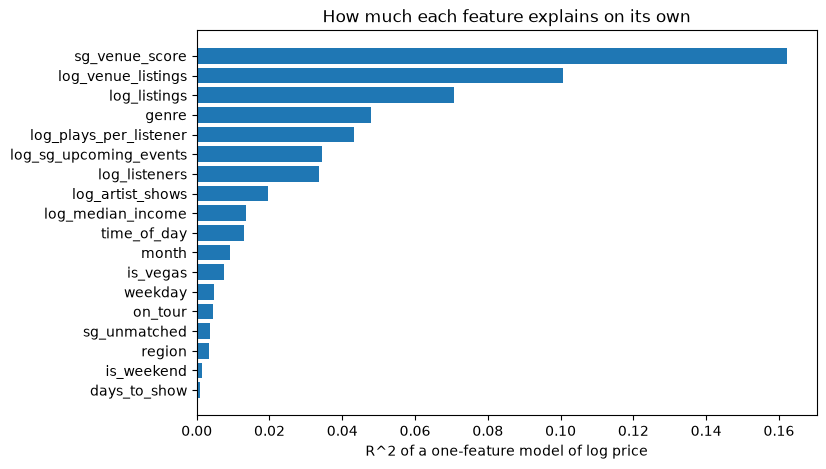

In [62]:
# same thing as a bar chart
fig, ax = plt.subplots(figsize=(8, 5))
ax.barh(alone["feature"], alone["R2 alone"])
ax.invert_yaxis()
ax.set(xlabel="R^2 of a one-feature model of log price", title="How much each feature explains on its own")
plt.show()

## 2.4 Price vs. popularity and Price vs. listings
Scatter plots of price against artist popularity and against the number of listings, with the median price in each tenth (decile) of the feature drawn on top. The y-axis is in dollars on a log scale, so equal steps mean equal **percentage** changes.

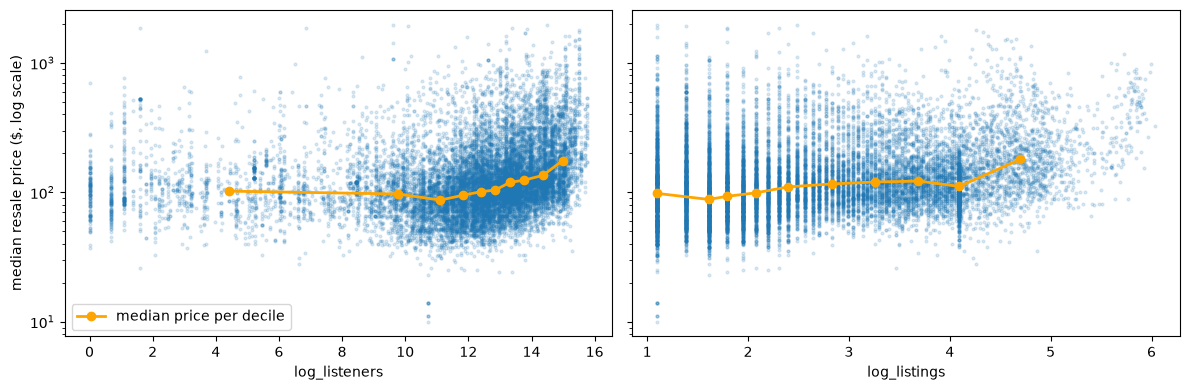

In [63]:
# price vs. popularity and vs. listings
# the orange line is the median price in each tenth (decile) of the feature
fig, axes = plt.subplots(1, 2, figsize=(12, 4), sharey=True)
for ax, f in zip(axes, ["log_listeners", "log_listings"]):
    ax.scatter(df[f], df["price_median"], s=4, alpha=0.15)
    df["decile"] = pd.qcut(df[f], 10, duplicates="drop")
    deciles = df.groupby("decile", observed=True)[[f, "price_median"]].median()
    ax.plot(deciles[f], deciles["price_median"], lw=2, marker="o", color="orange", label="median price per decile")
    ax.set(xlabel=f, yscale="log")
axes[0].set_ylabel("median resale price ($, log scale)")
axes[0].legend()
plt.tight_layout()
plt.show()

# dropping the helper column
df = df.drop(columns="decile")

## 2.5 Price by the categorical features
Box plots of price by genre, region, weekday and start time, with groups ordered by their median price.

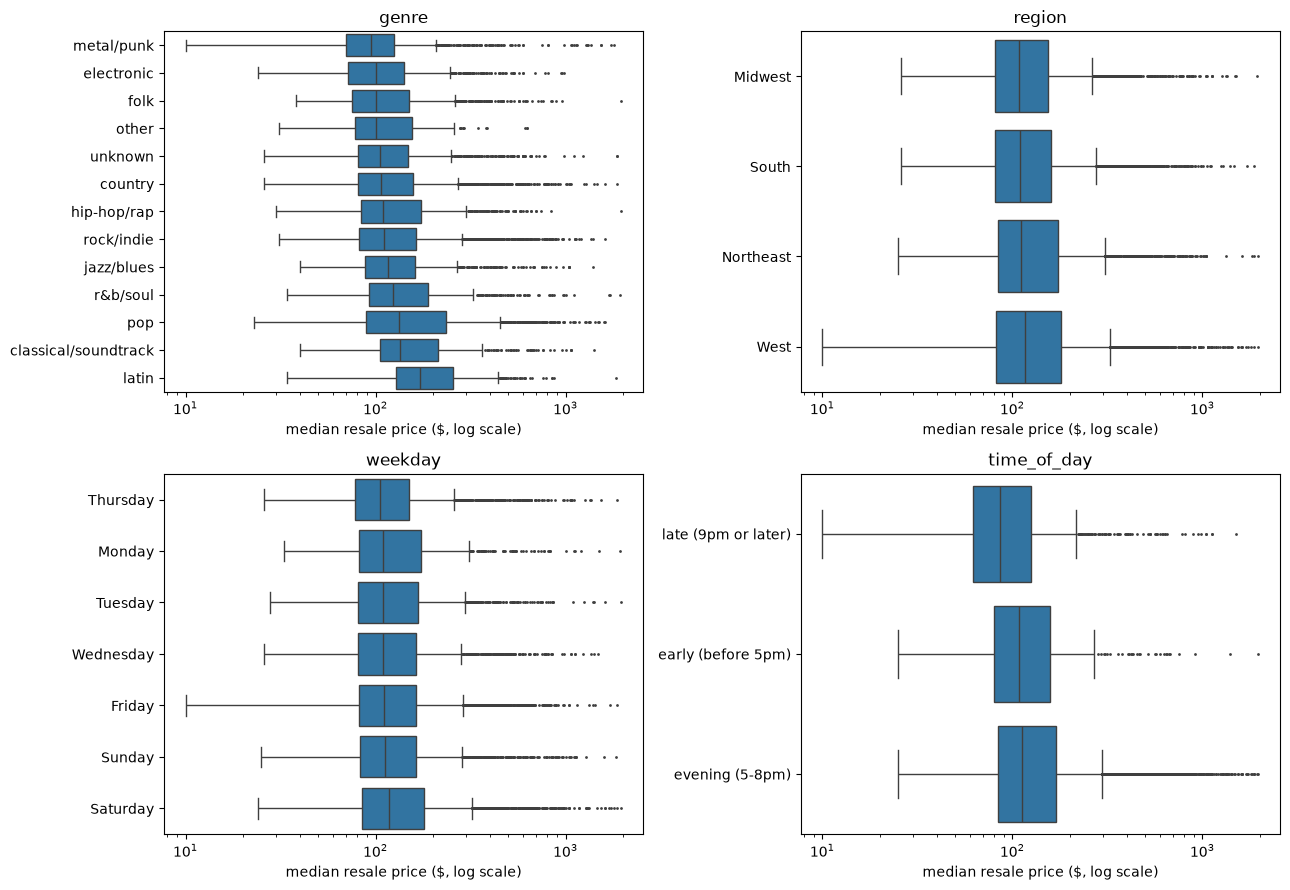

In [64]:
# box plots of price for each group, ordered by the median price
fig, axes = plt.subplots(2, 2, figsize=(13, 9))
for ax, f in zip(axes.flat, ["genre", "region", "weekday", "time_of_day"]):
    order = df.groupby(f)["price_median"].median().sort_values().index
    sns.boxplot(data=df, x="price_median", y=f, order=order, fliersize=1, ax=ax)
    ax.set(xscale="log", xlabel="median resale price ($, log scale)", ylabel="", title=f)
plt.tight_layout()
plt.show()

In [65]:
# number of shows and median price for each group
for f in ["genre", "region", "weekday", "time_of_day", "month", "is_weekend", "is_vegas", "on_tour"]:
    table = df.groupby(f)["price_median"].agg(["count", "median"]).sort_values("median")
    display(table.T)

genre,metal/punk,electronic,folk,other,unknown,country,hip-hop/rap,rock/indie,jazz/blues,r&b/soul,pop,classical/soundtrack,latin
count,1428.0,848.0,1032.0,201.0,1422.0,2094.0,834.0,3206.0,841.0,855.0,1328.0,457.0,538.0
median,95.0,100.0,100.0,101.0,106.0,107.0,110.0,111.0,116.0,124.0,133.0,134.0,170.5


region,Midwest,South,Northeast,West
count,3000.0,4518.0,2808.0,4758.0
median,108.0,109.0,111.0,116.0


weekday,Thursday,Monday,Tuesday,Wednesday,Friday,Sunday,Saturday
count,2314.0,616.0,1469.0,1632.0,3602.0,1922.0,3529.0
median,105.0,109.5,110.0,110.0,111.0,112.0,118.0


time_of_day,late (9pm or later),early (before 5pm),evening (5-8pm)
count,906.0,382.0,13796.0
median,86.0,108.5,113.0


month,11,10,9,7,8
count,1122.0,5404.0,4464.0,486.0,3608.0
median,101.0,109.0,110.0,117.5,119.0


is_weekend,0,1
count,7953.0,7131.0
median,109.0,114.0


is_vegas,0,1
count,14518.0,566.0
median,110.0,134.0


on_tour,0,1
count,10535.0,4549.0
median,109.0,116.0


## Part 2 summary: how the features relate

**Features that move together** (|r| > 0.5):

| Pair | r | What it means |
|---|---|---|
| `log_listings` & `log_venue_listings` | 0.86 | Both measure how big the show / venue is. Keeping both makes each coefficient hard to read (3.2) |
| `log_venue_listings` & `sg_venue_score` | 0.62 | Bigger venues get higher SeatGeek scores |
| `log_listeners` & `log_plays_per_listener` | 0.61 | Popular artists also have more devoted listeners. Related, but not the same thing |
| `log_listings` & `sg_venue_score` | 0.60 | Same venue-size idea as above |
| `sg_venue_score` & `log_sg_upcoming_events` | 0.56 | Busier venues score higher |

By construction, `is_weekend` is part of `weekday` (Friday + Saturday) and `is_vegas` is part of the West region.

**What relates to price on its own:**
- **Venue features come first:** `sg_venue_score` explains 16% of the variance in log price on its own, `log_venue_listings` 10% and `log_listings` 7%.
- **Artist features are next:** genre (4.8%), plays per listener (4.3%) and listeners (3.4%).
- **Timing and location features are each about 1% or less:** start time, month, Las Vegas, weekday, on tour, region, weekend. `days_to_show` explains almost nothing (0.1%), as expected: by design almost every snapshot is 14 days out.
- **No single feature explains much.** The box plots overlap heavily: price varies a lot *within* every genre, region and weekday.

**Patterns worth noting:**
- **Genre:** Latin has the highest median price ($171), then classical/soundtrack and pop (about $133). Metal/punk is the lowest ($95).
- **Las Vegas:** $134 median vs. $110 everywhere else. Regions differ by under $10 once Las Vegas is set aside (the West is highest at $116).
- **Saturday, not the weekend:** Saturday ($118) is the only day that stands out; Friday ($111) is no higher than a weekday.
- **Late shows are cheaper:** $86 for 9 pm or later vs. $113 for evening shows.
- **Month** differs a little (July-August highest, November lowest). We only have four months of shows, so we can't tell seasonality apart from the timing of the data collection.

# Part 3 - Feature selection
1. **Train/test split** and filling in missing values
2. **VIF** - which numeric features are too collinear to keep together, and a closer look at the high ones
3. **Forward and backward selection** (`SequentialFeatureSelector`) and **RFECV**, scored with 5-fold cross-validation as in class
4. **Lasso** - which coefficients are pushed to 0 as the penalty grows
5. **Interaction terms** - nested F-tests (Week 4 Part 2)
6. **Outliers and high leverage points** (Week 4 Part 2)

**Metric.** RMSE on the log price. (An RMSE of 0.5 on the log scale means a typical prediction is off by a factor of about e^0.5 = 1.65, roughly 65% too high or 40% too low)

## 3.1 Train/test split
We hold out 20% of **shows** as a test set and don't use it until the final model comparison in the modeling notebooks. All feature selection below uses the training shows only.

Note: the split is by show, so one artist's tour can have shows in both train and test. The model can partly learn an artist's price level from its training shows, so the test score will be a bit more optimistic than it would be for artists the model has never seen.

In [66]:
# random 80/20 split of the shows (same as class: train_test_split with a random state)
train, test = train_test_split(df, test_size=0.2, random_state=RANDOM_STATE)

# marking the split on the full table so the modeling notebooks use the same shows
df["split"] = "train"
df.loc[test.index, "split"] = "test"
print(df["split"].value_counts())

# how many artists have shows on both sides
both = set(train["artist_key"]) & set(test["artist_key"])
print("artists with shows in both train and test:", len(both))

split
train    12067
test      3017
Name: count, dtype: int64
artists with shows in both train and test: 1311


In [67]:
# filling the missing SeatGeek and income values with the TRAINING median
# (only the training data is used to fill, never the test data, like the mean imputation in lab 6)
FILL = ["sg_venue_score", "log_sg_upcoming_events", "log_median_income"]
train_medians = train[FILL].median()
print(train_medians)

for col in FILL:
    train[col] = train[col].fillna(train_medians[col])
    test[col] = test[col].fillna(train_medians[col])
    df[col] = df[col].fillna(train_medians[col])

print("missing values left in train:", train[CANDIDATES].isna().sum().sum())

sg_venue_score             0.590000
log_sg_upcoming_events     2.944439
log_median_income         11.311996
dtype: float64
missing values left in train: 0


## 3.2 VIF
The Variance Inflation Factor tells us how much a coefficient's variance is inflated because that feature can be predicted from the other features. As in class: a VIF above 5 is a warning, above 10 is a problem. We use the same `vif_table` function as the Week 4 Part 1 notebook, on the numeric and binary features.

In [68]:
# same vif_table function as the feature_selection_pt1 notebook
def vif_table(df, cols):
    X = sm.add_constant(df[cols])
    return pd.DataFrame({
        "variable": cols,
        "VIF": [variance_inflation_factor(X.values, X.columns.get_loc(c)) for c in cols],
    }).round(2)

vif = vif_table(train, NUMERIC + BINARY)
vif.sort_values("VIF", ascending=False)

,variable,VIF
1,log_venue_listings,4.15
0,log_listings,4.05
6,sg_venue_score,2.32
3,log_plays_per_listener,1.83
2,log_listeners,1.62
7,log_sg_upcoming_events,1.61
11,on_tour,1.20
4,log_artist_shows,1.11
9,is_weekend,1.06
5,days_to_show,1.05


**What the VIF shows.** Every VIF is below 5, so there is no serious multicollinearity. The two highest are `log_venue_listings` (4.2) and `log_listings` (4.1): the r = 0.86 pair from Part 2. Everything else is 2.3 or lower.

The next cell looks at that pair the same way the class did with `temp` and `atemp`.

In [ ]:
# looking at the highest VIF pair
# fit with only one of them, then with both, and compare the coefficient, standard error and R^2
others = "log_listeners + log_plays_per_listener + log_artist_shows + days_to_show + sg_venue_score + log_sg_upcoming_events + log_median_income + is_weekend + is_vegas + on_tour + sg_unmatched"

one = smf.ols(TARGET + " ~ log_venue_listings + " + others, data=train).fit()
both = smf.ols(TARGET + " ~ log_venue_listings + log_listings + " + others, data=train).fit()

comp = pd.DataFrame({
    "venue listings only": {"coef(log_venue_listings)": one.params["log_venue_listings"], "SE": one.bse["log_venue_listings"],
                            "t": one.tvalues["log_venue_listings"], "R^2": one.rsquared, "Adj. R^2": one.rsquared_adj},
    "both listings features": {"coef(log_venue_listings)": both.params["log_venue_listings"], "SE": both.bse["log_venue_listings"],
                               "t": both.tvalues["log_venue_listings"], "R^2": both.rsquared, "Adj. R^2": both.rsquared_adj},
}).T
print(comp.round(4))

print("coefficient on log_listings when both are in:", round(both.params["log_listings"], 4))
print("standard error:", round(both.bse["log_listings"], 4))

                        coef(log_venue_listings)      SE        t     R^2  \
venue listings only                       0.0738  0.0049  14.9683  0.1790   
both listings features                    0.1215  0.0080  15.1446  0.1829   

                        Adj. R^2  
venue listings only       0.1782  
both listings features    0.1820  
coefficient on log_listings when both are in: -0.067
standard error: 0.0089


**A cleaner way to keep both pieces of information.** `log_listings` and `log_venue_listings` overlap because a big venue has many listings at every show. Instead of the raw show listings, we can use the show's listings **compared with the venue's usual**: `log_listings_vs_venue = log_listings - log_venue_listings`. The pair then measures two separate things: how big the venue is, and whether this show has more or fewer listings than that venue usually does. The model's fit is exactly the same (it is the same information, re-expressed, like centering in class), but the VIF drops.

In [70]:
# making the new feature in all three tables
train["log_listings_vs_venue"] = train["log_listings"] - train["log_venue_listings"]
test["log_listings_vs_venue"] = test["log_listings"] - test["log_venue_listings"]
df["log_listings_vs_venue"] = df["log_listings"] - df["log_venue_listings"]

# swapping log_listings for the new feature in the candidate list
NUMERIC = ["log_listings_vs_venue", "log_venue_listings", "log_listeners", "log_plays_per_listener", "log_artist_shows",
           "days_to_show", "sg_venue_score", "log_sg_upcoming_events", "log_median_income"]
CANDIDATES = NUMERIC + CATEGORICAL + BINARY

# adding its R^2 on its own to the table from 2.3 (used in 3.7)
fit = smf.ols(TARGET + " ~ log_listings_vs_venue", data=df).fit()
alone = pd.concat([alone, pd.DataFrame([{"feature": "log_listings_vs_venue", "R2 alone": fit.rsquared, "rows used": fit.nobs}])])

# VIF again with the new feature
vif_table(train, NUMERIC + BINARY).sort_values("VIF", ascending=False)

,variable,VIF
6,sg_venue_score,2.32
1,log_venue_listings,1.99
3,log_plays_per_listener,1.83
2,log_listeners,1.62
7,log_sg_upcoming_events,1.61
0,log_listings_vs_venue,1.31
11,on_tour,1.20
4,log_artist_shows,1.11
9,is_weekend,1.06
5,days_to_show,1.05


In [71]:
# checking that the fit is the same, only the coefficients changed
both_v2 = smf.ols(TARGET + " ~ log_venue_listings + log_listings_vs_venue + " + others, data=train).fit()
print("R^2 with log_listings:", round(both.rsquared, 6))
print("R^2 with log_listings_vs_venue:", round(both_v2.rsquared, 6))

R^2 with log_listings: 0.182865
R^2 with log_listings_vs_venue: 0.182865


## 3.3 Preprocessing and cross-validation folds
The same setup as the class notebook:
- categorical features are one-hot encoded with the first level dropped (that level becomes the reference)
- everything is then standardized, so features on different scales can be compared
- 5-fold cross-validation with shuffling and a fixed random state, on the training shows only

In [72]:
# defining X and y from the training shows
X = train[CANDIDATES]
y = train[TARGET]

# one-hot encode the categorical columns as a preprocessing step (same as pt3 notebook)
# numeric and binary columns pass through unchanged
preprocess = make_column_transformer(
    (OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), CATEGORICAL),
    remainder="passthrough",
    verbose_feature_names_out=False,
)

# Creates a cross validator to split data into train/test splits
# Shuffle=True means that we are shuffling the data before selecting
# Setting a random state = reproducible output
cv = KFold(n_splits=5, shuffle=True, random_state=RANDOM_STATE)

# how many columns the model sees after one-hot encoding
column_names = list(preprocess.fit(X).get_feature_names_out())
n_columns = len(column_names)
print(len(CANDIDATES), "candidate features ->", n_columns, "columns after one-hot encoding")

18 candidate features -> 40 columns after one-hot encoding


In [73]:
# baseline: predicting the average log price for every show (any useful model has to beat this)
baseline = root_mean_squared_error(y, np.full(len(y), y.mean()))

# linear regression with all the candidates
full = make_pipeline(preprocess, StandardScaler(), LinearRegression())
full_rmse = -cross_val_score(full, X, y, cv=cv, scoring="neg_root_mean_squared_error").mean()

print("baseline RMSE (predict the mean):", round(baseline, 4))
print("all candidates, 5-fold CV RMSE:", round(full_rmse, 4))

baseline RMSE (predict the mean): 0.6143
all candidates, 5-fold CV RMSE: 0.5408


## 3.4 Forward and backward selection
`SequentialFeatureSelector` adds (forward) or removes (backward) one column at a time, and at each step keeps the change with the best 5-fold cross-validated RMSE (Week 5 + 6 notebook).

Instead of fixing the number of columns, we let it decide when to stop with `n_features_to_select="auto"` and a tolerance `tol`:
- **forward** stops when adding the best remaining column improves the CV score by less than `tol`
- **backward** stops when removing any column would make the CV score worse by more than `tol` (for backward, `tol` is given as a negative number)

We use `tol = 0.001`, i.e. a step has to change the CV RMSE by at least 0.001 on the log scale (about 0.1% of price) to count.

Note: it works on the **columns after one-hot encoding**, so it can keep some genre dummies and drop others. A dropped dummy merges into the reference group. When we summarize in 3.7, a categorical feature counts as selected if any of its dummies is selected.

In [74]:
# tolerance: a step has to change the CV RMSE by at least 0.001 to count
TOL = 0.001

# forward selection (pipeline from the pt3 notebook, but with n_features_to_select="auto")
forward = make_pipeline(
    preprocess, StandardScaler(),
    SequentialFeatureSelector(LinearRegression(), n_features_to_select="auto", tol=TOL,
                              direction="forward", cv=cv, n_jobs=-1,
                              scoring="neg_root_mean_squared_error"),
    LinearRegression())
forward.fit(X, y)
forward_cols = list(forward[:-1].get_feature_names_out())
print("Forward kept", len(forward_cols), "columns:")
print(forward_cols)

Forward kept 12 columns:
['genre_latin', 'genre_metal/punk', 'genre_pop', 'genre_unknown', 'weekday_Saturday', 'time_of_day_late (9pm or later)', 'log_listings_vs_venue', 'log_venue_listings', 'log_listeners', 'sg_venue_score', 'log_median_income', 'is_vegas']


In [75]:
# backward selection (for backward the tolerance is negative)
# this one is slow (1-3 minutes) since every step refits the model for each remaining column and fold
backward = make_pipeline(
    preprocess, StandardScaler(),
    SequentialFeatureSelector(LinearRegression(), n_features_to_select="auto", tol=-TOL,
                              direction="backward", cv=cv, n_jobs=-1,
                              scoring="neg_root_mean_squared_error"),
    LinearRegression())
backward.fit(X, y)
backward_cols = list(backward[:-1].get_feature_names_out())
print("Backward kept", len(backward_cols), "columns:")
print(backward_cols)

Backward kept 19 columns:
['genre_country', 'genre_electronic', 'genre_folk', 'genre_hip-hop/rap', 'genre_jazz/blues', 'genre_metal/punk', 'genre_other', 'genre_pop', 'genre_r&b/soul', 'genre_rock/indie', 'weekday_Saturday', 'time_of_day_late (9pm or later)', 'month_8', 'log_listings_vs_venue', 'log_listeners', 'log_plays_per_listener', 'sg_venue_score', 'log_median_income', 'is_vegas']


In [76]:
# encoding and scaling the training data once so we can pick out columns by name
X_encoded = pd.DataFrame(StandardScaler().fit_transform(preprocess.fit_transform(X)), columns=column_names)


def cv_rmse_columns(cols):
    # 5-fold CV RMSE of a linear regression on these encoded columns
    # (a little optimistic, since the same folds were used to pick the columns)
    scores = -cross_val_score(LinearRegression(), X_encoded[cols], y, cv=cv, scoring="neg_root_mean_squared_error")
    return scores.mean()


print("forward CV RMSE:", round(cv_rmse_columns(forward_cols), 4))
print("backward CV RMSE:", round(cv_rmse_columns(backward_cols), 4))
print("all columns CV RMSE:", round(full_rmse, 4))

print("in forward but not backward:", sorted(set(forward_cols) - set(backward_cols)))
print("in backward but not forward:", sorted(set(backward_cols) - set(forward_cols)))

forward CV RMSE: 0.5474
backward CV RMSE: 0.5424
all columns CV RMSE: 0.5408
in forward but not backward: ['genre_latin', 'genre_unknown', 'log_venue_listings']
in backward but not forward: ['genre_country', 'genre_electronic', 'genre_folk', 'genre_hip-hop/rap', 'genre_jazz/blues', 'genre_other', 'genre_r&b/soul', 'genre_rock/indie', 'log_plays_per_listener', 'month_8']


In [ ]:
# forward selection at different sizes k, like the k loop in lab 5 (takes about a minute)
rows = []
for k in [1, 2, 3, 4, 6, 8, 10, 15, 20]:
    pipe = make_pipeline(
        preprocess, StandardScaler(),
        SequentialFeatureSelector(LinearRegression(), n_features_to_select=k,
                                  direction="forward", cv=cv, n_jobs=-1,
                                  scoring="neg_root_mean_squared_error"),
        LinearRegression())
    pipe.fit(X, y)
    cols = list(pipe[:-1].get_feature_names_out())
    rows.append({"k": k, "cv_rmse": cv_rmse_columns(cols), "columns": cols})
forward_path = pd.DataFrame(rows)

# plotting CV RMSE against the number of columns
fig, ax = plt.subplots(figsize=(9, 4.5))
ax.plot(forward_path["k"], forward_path["cv_rmse"], "o-", label="forward selection")
ax.axhline(full_rmse, color="gray", ls=":", label="all columns")
ax.axhline(baseline, color="gray", ls="--", label="baseline (predict the mean)")
ax.set(xlabel="number of columns", ylabel="5-fold CV RMSE (log price)", title="Forward selection: error by model size")
ax.legend()
plt.show()

display(forward_path[["k", "cv_rmse"]].round(4))

## 3.5 RFECV: how many features?
RFE removes the column with the smallest (standardized) coefficient, refits, and repeats. **RFECV** scores every model size with the same 5 folds and picks the size with the lowest cross-validated RMSE, then refits RFE on all training shows to that size (Week 5 + 6 notebook).

In [ ]:
# RFECV pipeline (same as the pt3 notebook)
rfecv = make_pipeline(preprocess, StandardScaler(),
                      RFECV(LinearRegression(), cv=cv, scoring="neg_root_mean_squared_error"),
                      LinearRegression())
rfecv.fit(X, y)
rfecv_cols = list(rfecv[:-1].get_feature_names_out())

print("RFECV kept", rfecv[2].n_features_, "of", n_columns, "columns:")
print(rfecv_cols)

RFECV kept 35 of 40 columns:
['genre_country', 'genre_electronic', 'genre_folk', 'genre_hip-hop/rap', 'genre_jazz/blues', 'genre_metal/punk', 'genre_other', 'genre_pop', 'genre_r&b/soul', 'genre_rock/indie', 'genre_unknown', 'region_Northeast', 'region_South', 'region_West', 'weekday_Saturday', 'weekday_Sunday', 'weekday_Thursday', 'time_of_day_evening (5-8pm)', 'time_of_day_late (9pm or later)', 'month_11', 'month_7', 'month_8', 'log_listings_vs_venue', 'log_venue_listings', 'log_listeners', 'log_plays_per_listener', 'log_artist_shows', 'days_to_show', 'sg_venue_score', 'log_sg_upcoming_events', 'log_median_income', 'is_weekend', 'is_vegas', 'on_tour', 'sg_unmatched']


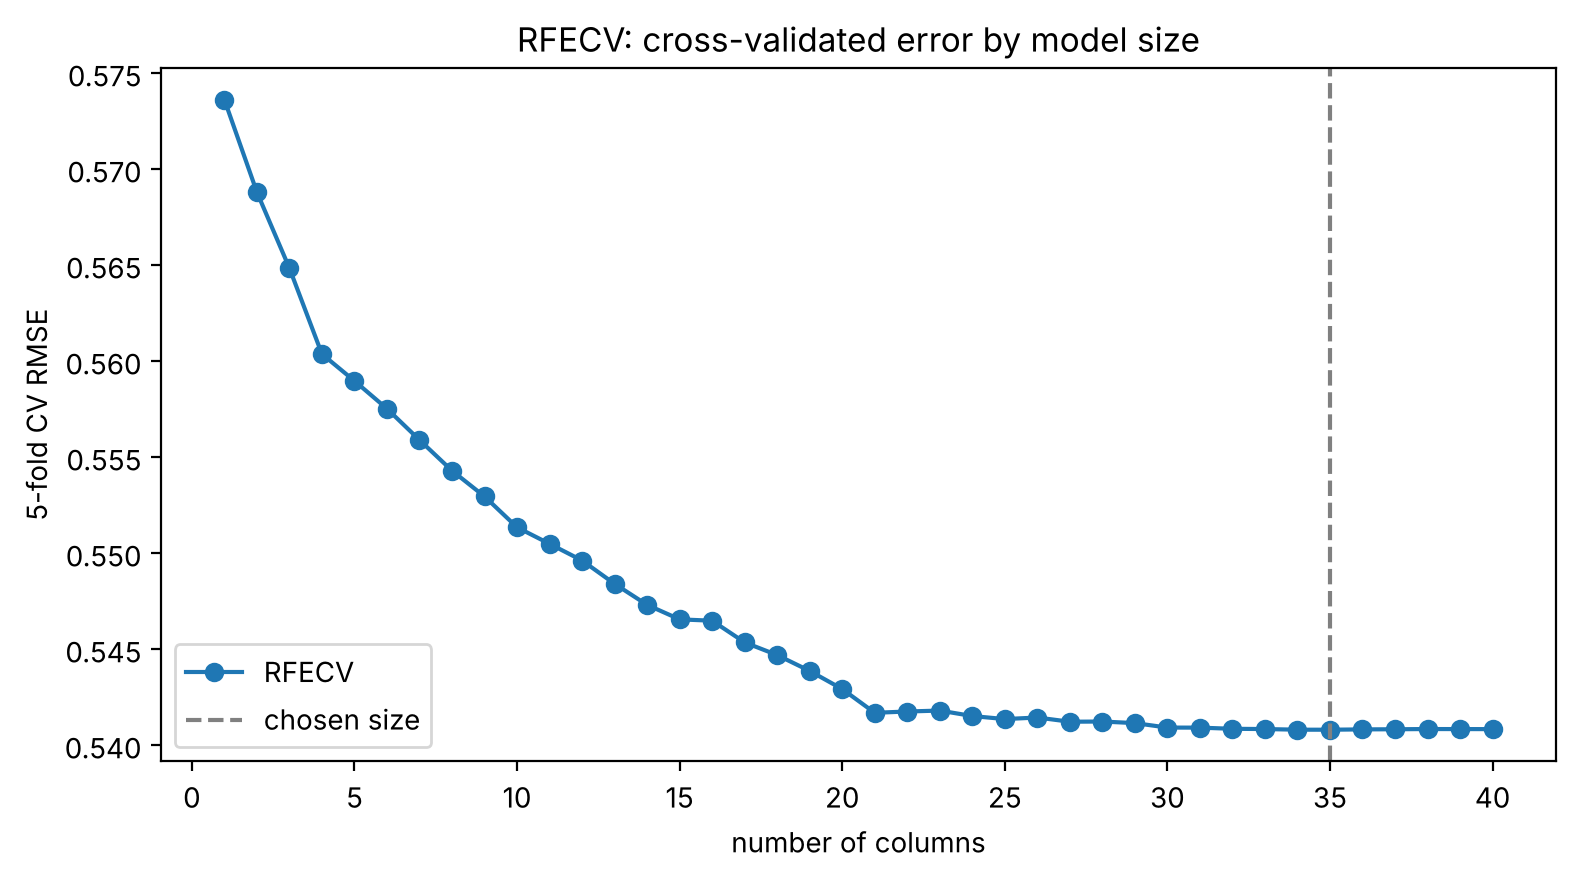

In [ ]:
# CV RMSE at every model size (RFECV saves these in cv_results_), plotted like the pt3 notebook
results = rfecv[2].cv_results_

plt.figure(figsize=(9, 4.5))
plt.plot(results["n_features"], -results["mean_test_score"], "o-", label="RFECV")
plt.axvline(rfecv[2].n_features_, color="gray", ls="--", label="chosen size")
plt.xlabel("number of columns")
plt.ylabel("5-fold CV RMSE")
plt.title("RFECV: cross-validated error by model size")
plt.legend()
plt.show()

In [ ]:
# the curve is very flat near the best size, so we also find the smallest size within one standard error of the best
rfe_table = pd.DataFrame({"n_columns": results["n_features"],
                          "rmse": -results["mean_test_score"],
                          "se": results["std_test_score"] / np.sqrt(5)})

best = rfe_table.loc[rfe_table["rmse"].idxmin()]
cutoff = best["rmse"] + best["se"]
one_se = rfe_table[rfe_table["rmse"] <= cutoff].iloc[0]

print("best size:", int(best["n_columns"]), "columns, RMSE", round(best["rmse"], 4), "SE", round(best["se"], 4))
print("smallest size within one SE:", int(one_se["n_columns"]), "columns, RMSE", round(one_se["rmse"], 4))

best size: 35 columns, RMSE 0.5408 SE 0.0018
smallest size within one SE: 21 columns, RMSE 0.5417


## 3.6 Lasso
The lasso is a linear regression with a penalty on the size of the coefficients. As the penalty `alpha` grows, the weakest coefficients are pushed to **exactly 0**, so the lasso also selects features. Here it is used to see which features it keeps, not as a final model.

All columns are standardized (dummies included) so the penalty treats every column the same way. `LassoCV` tries 100 values of `alpha` and picks the one with the lowest cross-validated error, on the same 5 folds (as in lab 6).

In [ ]:
# LassoCV in a pipeline with StandardScaler (same as lab 6)
lasso = make_pipeline(preprocess, StandardScaler(), LassoCV(cv=cv, random_state=RANDOM_STATE))
lasso.fit(X, y)
lasso_results = lasso[-1]

lasso_rmse = -cross_val_score(lasso, X, y, cv=cv, scoring="neg_root_mean_squared_error").mean()
print("The chosen penalty for the Lasso model is:", lasso_results.alpha_)
print("5-fold CV RMSE of the lasso:", round(lasso_rmse, 4))

The chosen penalty for the Lasso model is: 0.00022010202956691824
5-fold CV RMSE of the lasso: 0.5408


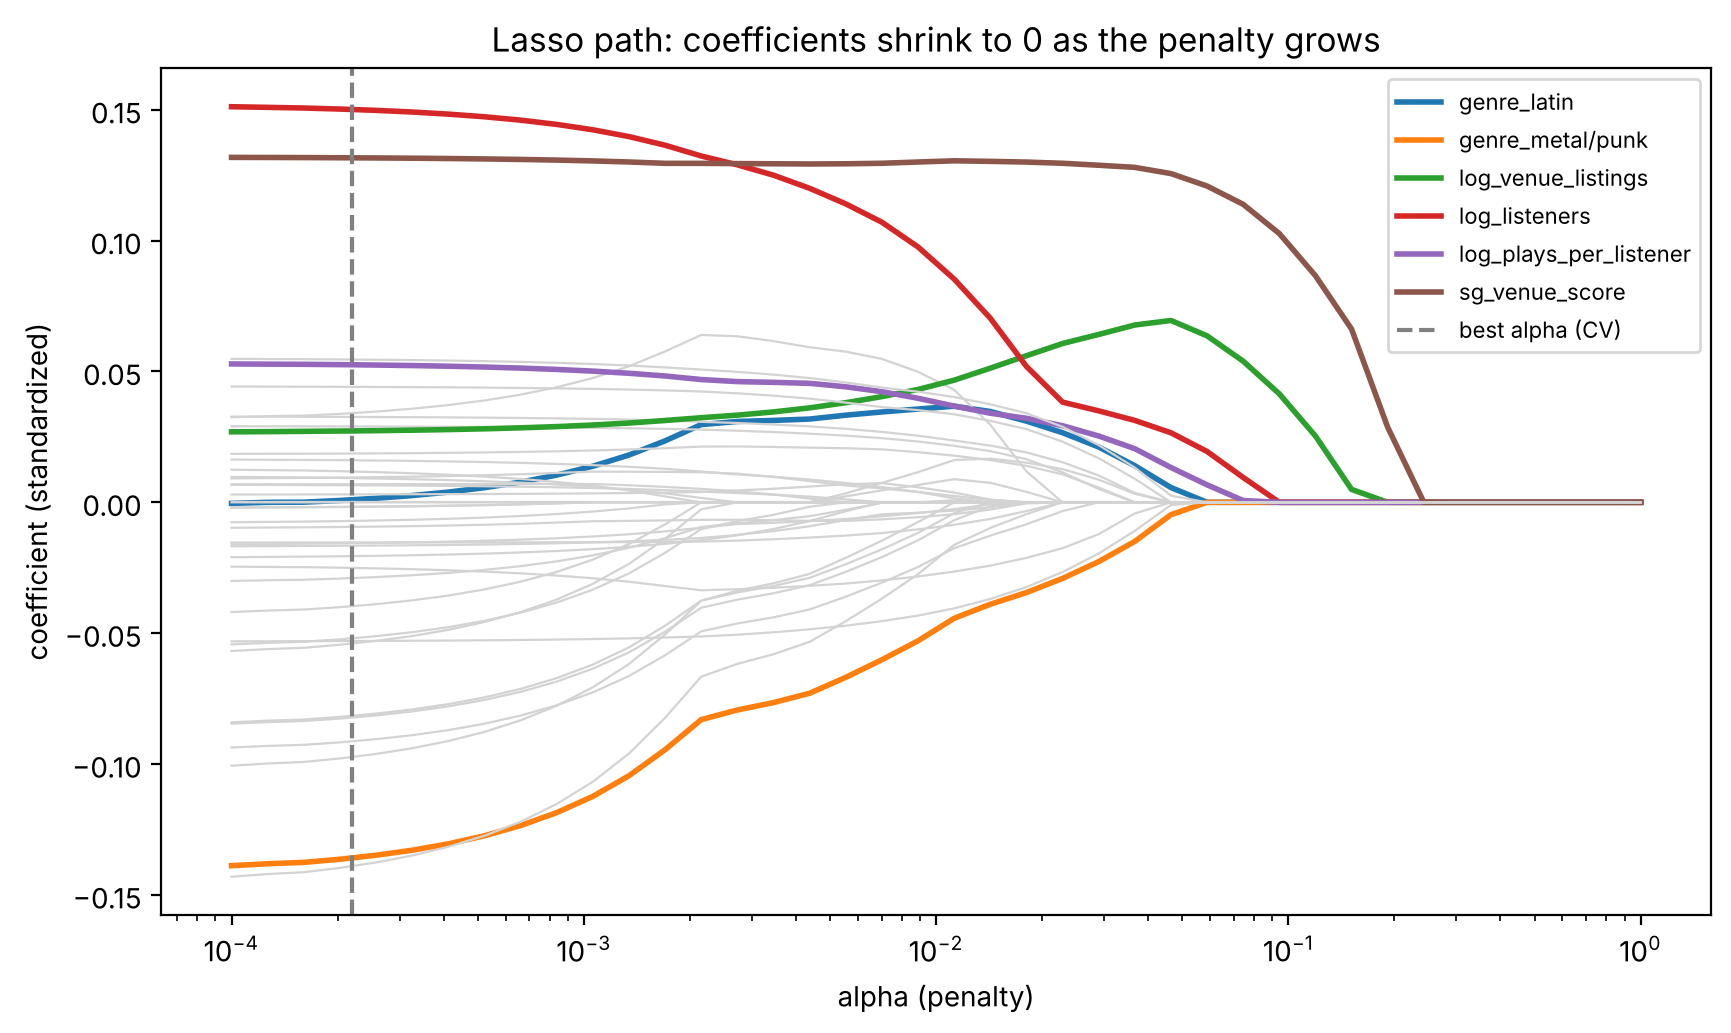

In [ ]:
# lasso path: the coefficients for a range of alphas (lasso_path from lab 6)
# small alpha = almost regular linear regression, large alpha = more coefficients pushed to 0
alphas = np.logspace(-4, 0, 40)
alphas_path, coefs_path, _ = lasso_path(X_encoded, y, alphas=alphas)
path = pd.DataFrame(coefs_path.T, index=alphas_path, columns=column_names)

# for each column: the largest alpha where it is still not 0 (bigger = survives longer)
last_alpha = {}
for col in column_names:
    nonzero = path.index[path[col] != 0]
    if len(nonzero) > 0:
        last_alpha[col] = nonzero.max()
    else:
        last_alpha[col] = 0
last_alpha = pd.Series(last_alpha).sort_values(ascending=False)

# plotting: the 6 columns that last the longest in color, everything else in gray
top6 = list(last_alpha.index[:6])
fig, ax = plt.subplots(figsize=(10, 5.5))
for col in column_names:
    if col in top6:
        ax.plot(path.index, path[col], lw=2, label=col)
    else:
        ax.plot(path.index, path[col], lw=0.8, color="lightgray")
ax.axvline(lasso_results.alpha_, color="gray", ls="--", label="best alpha (CV)")
ax.set(xscale="log", xlabel="alpha (penalty)", ylabel="coefficient (standardized)",
       title="Lasso path: coefficients shrink to 0 as the penalty grows")
ax.legend(fontsize=8)
plt.show()

In [ ]:
# table of how long each column survives and its coefficient at the best alpha
survives = pd.DataFrame({"last alpha not 0": last_alpha,
                         "coef at best alpha": pd.Series(lasso_results.coef_, index=column_names)})
survives = survives.sort_values("last alpha not 0", ascending=False)
display(survives.round(4))

lasso_cols = list(survives.index[survives["coef at best alpha"] != 0])
print("columns set to 0 at the best alpha:", list(survives.index[survives["coef at best alpha"] == 0]))

,last alpha not 0,coef at best alpha
sg_venue_score,0.1914,0.1316
log_venue_listings,0.1512,0.0273
log_listeners,0.0744,0.1501
log_plays_per_listener,0.0744,0.0526
genre_latin,0.0464,0.0009
genre_metal/punk,0.0464,-0.1359
is_vegas,0.0464,0.0546
log_listings_vs_venue,0.0464,-0.0530
month_8,0.0367,0.0326
time_of_day_late (9pm or later),0.0367,-0.0250


columns set to 0 at the best alpha: ['month_9', 'weekday_Monday']


## 3.7 Comparing the methods
One row per candidate feature. A categorical feature counts as selected by a method if **any** of its dummy columns was selected. The forward and backward columns use the selections from 3.4.

In [ ]:
def column_to_feature(col):
    # turns an encoded column name (e.g. "genre_pop") back into its feature ("genre")
    if col in CANDIDATES:
        return col
    for f in CATEGORICAL:
        if col.startswith(f + "_"):
            return f


def features_from_columns(cols):
    # the set of features that have at least one column in the list
    feats = set()
    for col in cols:
        feats.add(column_to_feature(col))
    return feats


forward_feats = features_from_columns(forward_cols)
backward_feats = features_from_columns(backward_cols)
rfecv_feats = features_from_columns(rfecv_cols)
lasso_feats = features_from_columns(lasso_cols)

# one row per feature: True if that method kept it
rows = []
for f in CANDIDATES:
    rows.append({"feature": f,
                 "forward": f in forward_feats,
                 "backward": f in backward_feats,
                 "RFECV": f in rfecv_feats,
                 "lasso (best alpha)": f in lasso_feats})
compare = pd.DataFrame(rows).set_index("feature")
compare["votes"] = compare.sum(axis=1)
compare = compare.join(alone.set_index("feature")["R2 alone"].round(4))
compare.sort_values(["votes", "R2 alone"], ascending=False)

,forward,backward,RFECV,lasso (best alpha),votes,R2 alone
feature,,,,,,
sg_venue_score,True,True,True,True,4,0.1623
genre,True,True,True,True,4,0.0479
log_listeners,True,True,True,True,4,0.0336
log_listings_vs_venue,True,True,True,True,4,0.0247
log_median_income,True,True,True,True,4,0.0136
time_of_day,True,True,True,True,4,0.0131
is_vegas,True,True,True,True,4,0.0074
weekday,True,True,True,True,4,0.0047
log_venue_listings,True,False,True,True,3,0.1005


In [ ]:
# how long each feature survives in the lasso path (the longest of any of its columns)
survives["feature"] = survives.index.map(column_to_feature)
survives.groupby("feature")["last alpha not 0"].max().sort_values(ascending=False).round(4)

feature
sg_venue_score            0.1914
log_venue_listings        0.1512
log_listeners             0.0744
log_plays_per_listener    0.0744
log_listings_vs_venue     0.0464
genre                     0.0464
is_vegas                  0.0464
month                     0.0367
log_median_income         0.0367
time_of_day               0.0367
log_artist_shows          0.0289
weekday                   0.0289
sg_unmatched              0.0180
region                    0.0143
is_weekend                0.0143
on_tour                   0.0055
days_to_show              0.0022
log_sg_upcoming_events    0.0017
Name: last alpha not 0, dtype: float64

## 3.8 Interaction terms
Does the effect of one feature depend on another? As in Week 4 Part 2, we fit an **additive** model and the same model with an **interaction**, then use a nested F-test (`anova_lm`) to see whether the interaction improves the fit more than chance would.

Two interactions that make sense for ticket prices:
1. **popularity x venue size**: does popularity matter more at big venues (more seats to fill, or more fans competing for them)?
2. **popularity x Las Vegas**: Las Vegas has many residencies and tourist crowds; does popularity work differently there?

As in class, the numeric features are **centered** first (minus their mean). That doesn't change the fit, but it makes the main-effect coefficients mean "the effect at an average show" and lowers the VIF of the interaction terms.

In [ ]:
# centering the two numeric features in the interaction (doesn't change the fit, like the pt2 notebook)
train["listeners_c"] = train["log_listeners"] - train["log_listeners"].mean()
train["venue_c"] = train["log_venue_listings"] - train["log_venue_listings"].mean()

# the other features in the model
base = "sg_venue_score + log_plays_per_listener + C(genre) + log_listings_vs_venue + is_vegas + C(weekday)"

additive = smf.ols(TARGET + " ~ listeners_c + venue_c + " + base, data=train).fit()
interaction = smf.ols(TARGET + " ~ listeners_c * venue_c + " + base, data=train).fit()

# nested F-test to see if the interaction model is better
print(sm.stats.anova_lm(additive, interaction))
print("interaction coefficient:", round(interaction.params["listeners_c:venue_c"], 4))
print("p-value:", round(interaction.pvalues["listeners_c:venue_c"], 4))
print("Adj. R^2 additive:", round(additive.rsquared_adj, 4))
print("Adj. R^2 interaction:", round(interaction.rsquared_adj, 4))

   df_resid          ssr  df_diff   ss_diff         F    Pr(>F)
0   12042.0  3571.335852      0.0       NaN       NaN       NaN
1   12041.0  3570.944697      1.0  0.391155  1.318951  0.250803
interaction coefficient: 0.0015
p-value: 0.2508
Adj. R^2 additive: 0.2142
Adj. R^2 interaction: 0.2142


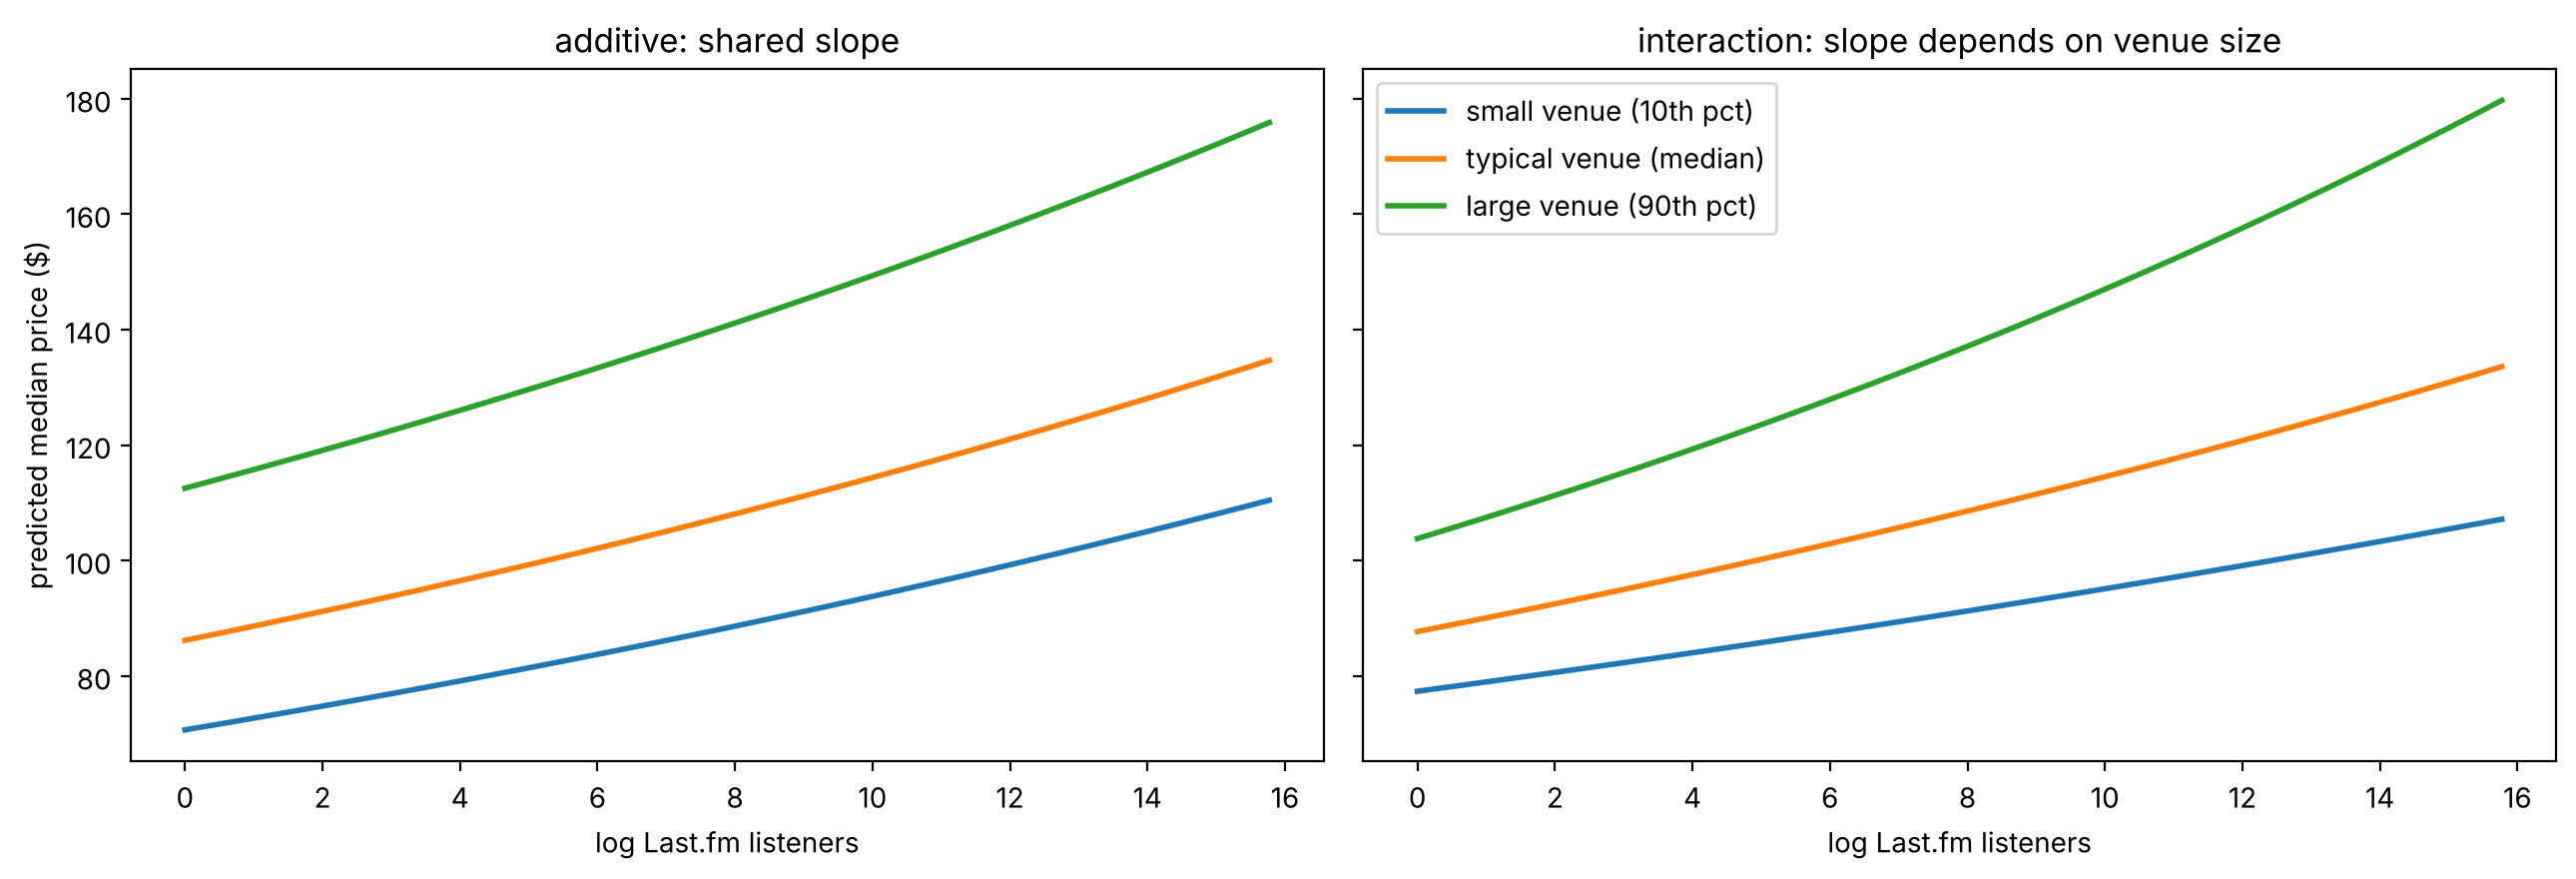

In [ ]:
# plotting like the penguin plot in the pt2 notebook
# simple models with just popularity and venue size, so the lines are easy to draw
small_add = smf.ols(TARGET + " ~ listeners_c + venue_c", data=train).fit()
small_int = smf.ols(TARGET + " ~ listeners_c * venue_c", data=train).fit()

grid = np.linspace(train["listeners_c"].min(), train["listeners_c"].max(), 50)
sizes = {"small venue (10th pct)": train["venue_c"].quantile(0.1),
         "typical venue (median)": train["venue_c"].median(),
         "large venue (90th pct)": train["venue_c"].quantile(0.9)}

fig, axes = plt.subplots(1, 2, figsize=(13, 4.5), sharey=True)
for ax, model, title in [(axes[0], small_add, "additive: shared slope"),
                         (axes[1], small_int, "interaction: slope depends on venue size")]:
    for label in sizes:
        pred = model.predict(pd.DataFrame({"listeners_c": grid, "venue_c": sizes[label]}))
        ax.plot(grid + train["log_listeners"].mean(), np.exp(pred), lw=2, label=label)
    ax.set(title=title, xlabel="log Last.fm listeners")
axes[0].set_ylabel("predicted median price ($)")
axes[1].legend()
plt.tight_layout()
plt.show()

In [ ]:
# second interaction: popularity x Las Vegas
interaction2 = smf.ols(TARGET + " ~ listeners_c * is_vegas + venue_c + " + base, data=train).fit()

print(sm.stats.anova_lm(additive, interaction2))
print("interaction coefficient:", round(interaction2.params["listeners_c:is_vegas"], 4))
print("p-value:", round(interaction2.pvalues["listeners_c:is_vegas"], 6))

   df_resid          ssr  df_diff   ss_diff          F    Pr(>F)
0   12042.0  3571.335852      0.0       NaN        NaN       NaN
1   12041.0  3566.434615      1.0  4.901237  16.547561  0.000048
interaction coefficient: 0.0253
p-value: 4.8e-05


In [ ]:
# does the interaction help on held-out data? 5-fold CV RMSE for each model with the same folds
# (with 12,000 shows even very small effects can be "significant" in the F-test)
def cv_rmse_formula(formula):
    errors = []
    for fit_idx, val_idx in cv.split(train):
        fit = smf.ols(formula, data=train.iloc[fit_idx]).fit()
        val = train.iloc[val_idx]
        errors.append(root_mean_squared_error(val[TARGET], fit.predict(val)))
    return np.mean(errors)


rows = []
rows.append({"model": "additive", "cv_rmse": cv_rmse_formula(TARGET + " ~ listeners_c + venue_c + " + base)})
rows.append({"model": "+ listeners x venue size", "cv_rmse": cv_rmse_formula(TARGET + " ~ listeners_c * venue_c + " + base)})
rows.append({"model": "+ listeners x Las Vegas", "cv_rmse": cv_rmse_formula(TARGET + " ~ listeners_c * is_vegas + venue_c + " + base)})
display(pd.DataFrame(rows).round(4))

,model,cv_rmse
0,additive,0.5452
1,+ listeners x venue size,0.5452
2,+ listeners x Las Vegas,0.5448


## 3.9 Outliers and high leverage points
Three different things (Week 4 Part 2):
- **outlier**: a show whose price is far from what the model predicts (large studentized residual, |r| > 3)
- **high leverage**: a show with unusual feature values (hat value h > 2(p+1)/n)
- **influential**: a show that changes the fitted coefficients a lot when removed (Cook's D > 4/n)

We fit a working model on the training shows and compute all three with `OLSInfluence`.

In [ ]:
# fitting a working model on the training shows
model = smf.ols(TARGET + " ~ log_listeners + log_venue_listings + " + base, data=train).fit()
infl = OLSInfluence(model) # Class that calculates outlier and influence measures for an OLS result

n, p = int(model.nobs), model.df_model
print("n =", n, " p =", int(p), " R^2 =", round(model.rsquared, 3))

n = 12067  p = 24  R^2 = 0.216


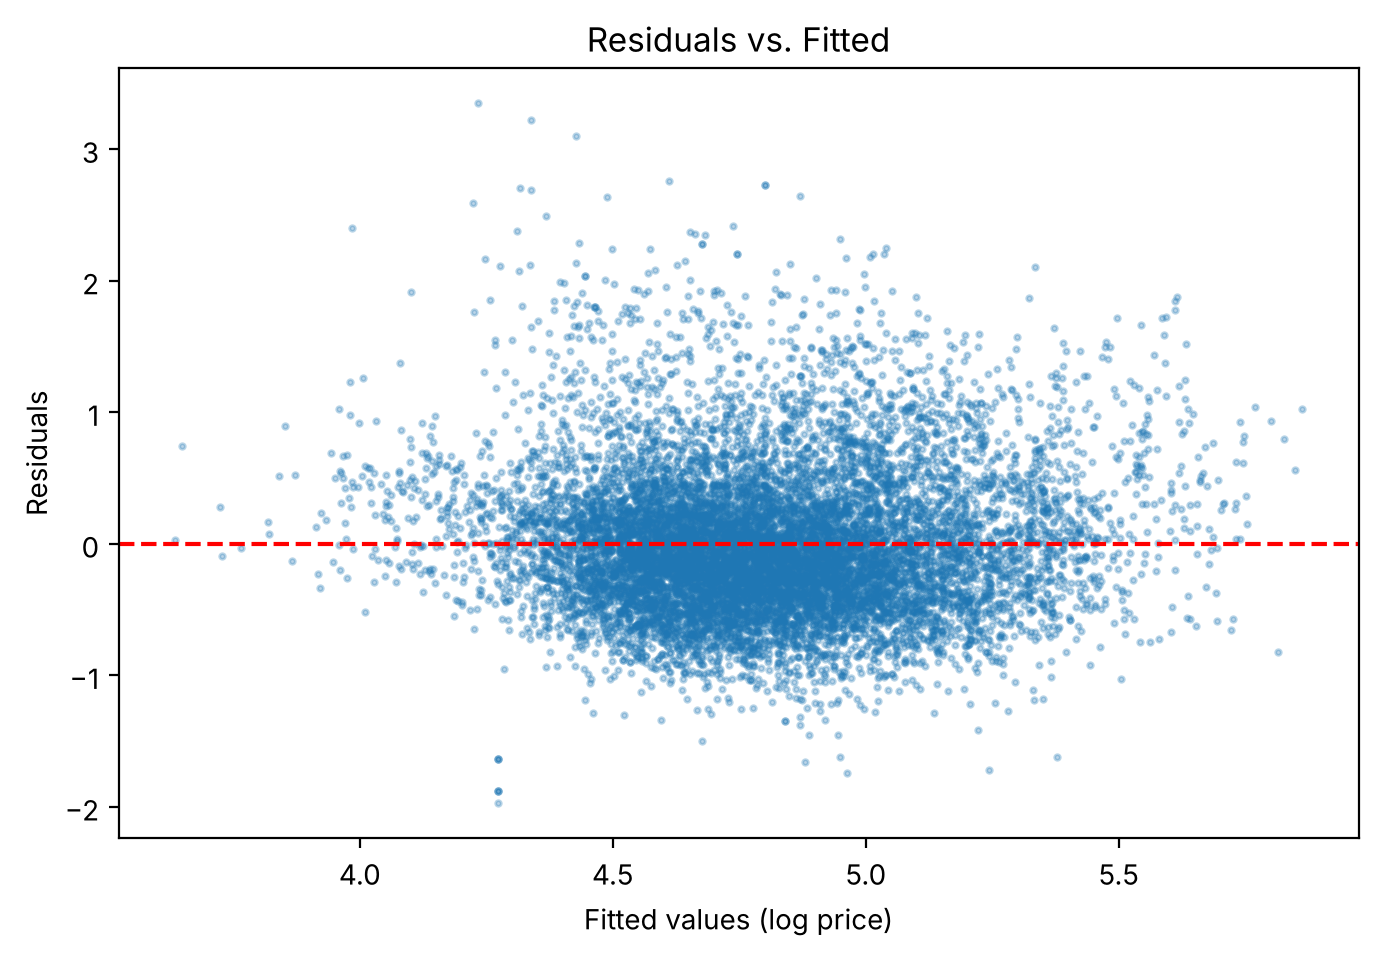

In [ ]:
# Let's plot fitted vs residuals
fig, ax = plt.subplots(figsize=(8, 5))
ax.scatter(model.fittedvalues, model.resid, s=4, alpha=0.3)
ax.axhline(0, color="red", linestyle="--")
ax.set_xlabel("Fitted values (log price)")
ax.set_ylabel("Residuals")
ax.set_title("Residuals vs. Fitted")
plt.show()

In [ ]:
# Now let's build a dataframe calculating metrics for residuals, leverage, and cooks_d
diag = pd.DataFrame({
    "name":          train["name"],
    "venue":         train["venue"],
    "price":         train["price_median"],
    "listings":      train["listings"],
    "fitted_price":  np.exp(model.fittedvalues).round(0),
    "student_resid": infl.resid_studentized_external,
    "leverage":      infl.hat_matrix_diag,
    "cooks_d":       infl.cooks_distance[0],
})

# cutoff values from the slides
lev_cut, cook_cut = 2 * (p + 1) / n, 4 / n
print("leverage cutoff =", round(lev_cut, 4), "  Cook's D cutoff =", round(cook_cut, 5))

# Count of observations that get flagged by each diagnostic
print("outliers (|studentized resid| > 3):", (diag.student_resid.abs() > 3).sum())
print("high leverage (h > 2(p+1)/n):", (diag.leverage > lev_cut).sum())
print("influential (Cook's D > 4/n):", (diag.cooks_d > cook_cut).sum())

leverage cutoff = 0.0041   Cook's D cutoff = 0.00033
outliers (|studentized resid| > 3): 165
high leverage (h > 2(p+1)/n): 426
influential (Cook's D > 4/n): 658


In [ ]:
# Which shows are the outliers (biggest residuals first)
outliers = diag[diag.student_resid.abs() > 3]
outliers.sort_values("student_resid", ascending=False).head(15).round(3)

,name,venue,price,listings,fitted_price,student_resid,leverage,cooks_d
2555,Will Sheff (of Okkervil River),Soda Bar,1966,3,69.0,6.168,0.002,0.004
2478,Playlunch (18+ Event),Schubas,1927,4,77.0,5.944,0.004,0.006
9814,The Carolina Opry,The Carolina Opry,1865,10,84.0,5.712,0.002,0.002
3286,ANEES,Moonshine Beach,1593,3,101.0,5.080,0.002,0.002
7694,Utah Symphony - A Night in Greece - Ravels Dap...,Abravanel Hall,1865,3,122.0,5.024,0.002,0.002
2973,Steve Earle,The Stephen Talkhouse,1860,6,122.0,5.017,0.001,0.001
179,Brotherkenzie,Empty Bottle,1124,3,75.0,4.981,0.001,0.001
3203,Kill Lincoln,The Roxy at Mahall’s,1129,3,77.0,4.951,0.002,0.002
3241,Gipsy Kings featuring Tonino Baliardo,The Clubhouse Hamptons,1833,6,130.0,4.867,0.003,0.003
1751,Trombone Shorty and Orleans Avenue,Denver Botanic Gardens,1242,8,89.0,4.847,0.002,0.002


In [ ]:
# Which shows have the highest leverage
diag.sort_values("leverage", ascending=False).head(10).round(4)

,name,venue,price,listings,fitted_price,student_resid,leverage,cooks_d
13554,KPOP x The World - Friday,Alamodome,627,4,179.0,2.3191,0.0106,0.0023
14794,Miel San Marcos,Long Beach Terrace Theater,133,25,75.0,1.0575,0.0094,0.0004
8420,Lenny Pearce,The Fillmore,91,12,52.0,1.0160,0.0092,0.0004
682,B Praak,The Chelsea at the Cosmopolitan,212,30,157.0,0.5483,0.0089,0.0001
13155,Boy Harsher,Republic NOLA,143,4,116.0,0.3836,0.0088,0.0001
13505,Voila (Moved from Nile Theater - Mesa),The Van Buren,127,16,83.0,0.7791,0.0086,0.0002
1615,Dale Watson and His Lone Stars,Shank Hall,69,6,72.0,-0.0808,0.0086,0.0000
12016,Idan Raichel,City Winery Philadelphia,147,5,99.0,0.7363,0.0085,0.0002
13153,Lenny Pearce,Channel 24,93,3,102.0,-0.1670,0.0085,0.0000
6580,Miel San Marcos,The Anthem,150,12,113.0,0.5274,0.0084,0.0001


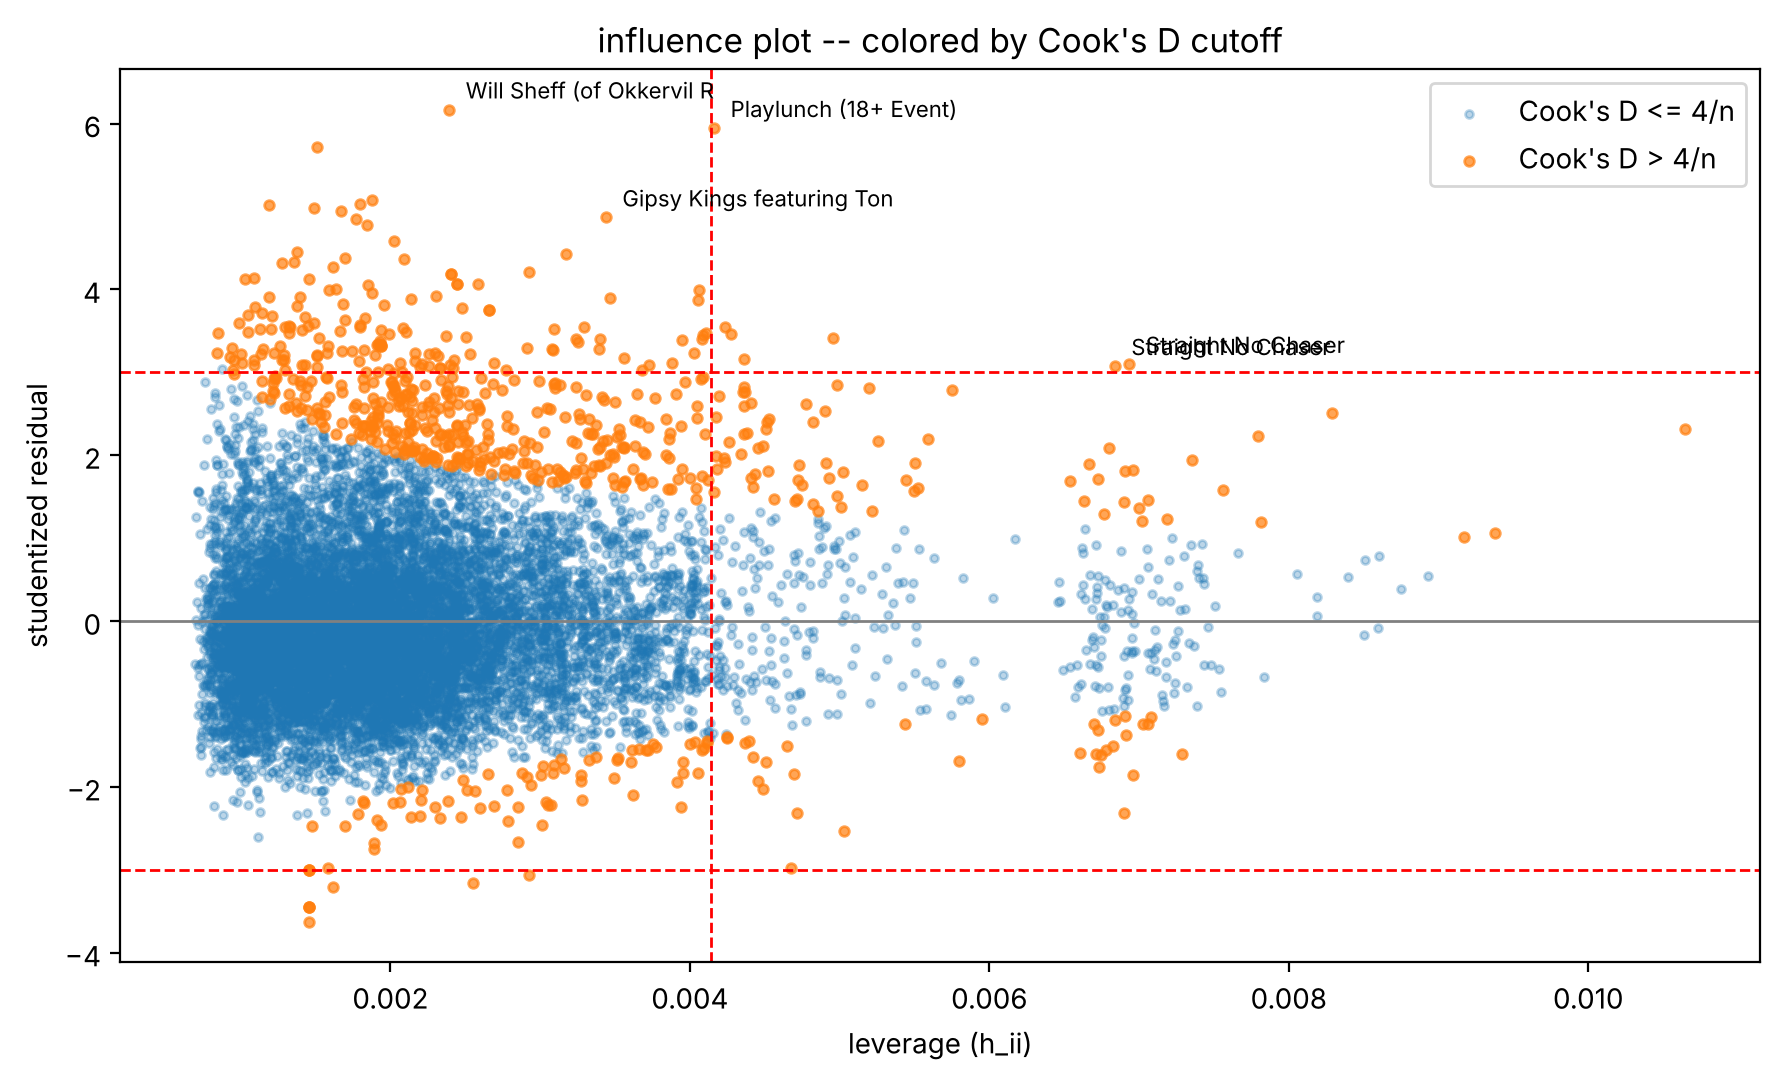

In [ ]:
# Plot all three at once: studentized residual vs. leverage, colored by Cook's D cutoff (from the pt2 notebook)
infl_flag = diag.cooks_d > cook_cut

fig, ax = plt.subplots(figsize=(9, 5.5))
ax.scatter(diag.leverage[~infl_flag], diag.student_resid[~infl_flag], s=8, alpha=0.3,
           color="tab:blue", label="Cook's D <= 4/n")
ax.scatter(diag.leverage[infl_flag], diag.student_resid[infl_flag], s=12, alpha=0.7,
           color="tab:orange", label="Cook's D > 4/n")
ax.axhline(0, color="gray", lw=1)
for yline in (-3, 3):
    ax.axhline(yline, color="red", ls="--", lw=1)
ax.axvline(lev_cut, color="red", ls="--", lw=1)
ax.set(xlabel="leverage (h_ii)", ylabel="studentized residual",
       title="influence plot -- colored by Cook's D cutoff")
ax.legend()

# labeling the 5 most influential shows
for _, r in diag.nlargest(5, "cooks_d").iterrows():
    ax.annotate(r["name"][:25], (r.leverage, r.student_resid), fontsize=8, xytext=(6, 4), textcoords="offset points")
plt.tight_layout()
plt.show()

In [ ]:
# Impact of removing influential points (same as the pt2 notebook)
keep = diag.cooks_d <= cook_cut
trimmed = smf.ols(TARGET + " ~ log_listeners + log_venue_listings + " + base, data=train[keep]).fit()

terms = ["log_listeners", "log_venue_listings", "sg_venue_score", "log_plays_per_listener", "log_listings_vs_venue", "is_vegas"]
print(pd.DataFrame({
    "all data": model.params[terms],
    "influential dropped": trimmed.params[terms],
    "% change": 100 * (trimmed.params[terms] - model.params[terms]) / model.params[terms].abs(),
}).round(4))
print("dropped", (~keep).sum(), "of", n, "shows")
print("R^2:", round(model.rsquared, 4), "->", round(trimmed.rsquared, 4))

                        all data  influential dropped  % change
log_listeners             0.0513               0.0555    8.2198
log_venue_listings        0.0335               0.0441   31.8205
sg_venue_score            0.8783               0.8932    1.6954
log_plays_per_listener    0.0697               0.0502  -27.8710
log_listings_vs_venue    -0.0722              -0.0664    8.1571
is_vegas                  0.2393               0.1973  -17.5721
dropped 658 of 12067 shows
R^2: 0.2158 -> 0.2972


**What the outlier check found:**
- **165 outliers** (|studentized residual| > 3), almost all far **above** the predicted price: $900-$1,966 tickets at small clubs with 3-10 listings where the model expects about $70-$130. Several have the same odd price, **$1,865** (The Carolina Opry, a Utah Symphony show), the same reseller placeholder price 08's first version found. They got past 07's placeholder rule because the cheapest ticket isn't 10 times lower.
- **426 high-leverage shows** are unusual combinations of feature values (a K-pop show at the Alamodome, artists with odd Last.fm numbers), but most have small residuals, so they don't pull the fit much.
- **658 influential shows** (Cook's D > 4/n, about 5% of the training shows). Dropping them raises R² from 0.22 to 0.30. Most coefficients keep their sign and size, but the venue-size coefficient grows by about 30% and plays per listener shrinks by about 30%.

**What to do with them.** We **keep** these shows. Dropping shows because the model fits them badly makes the model look better than it is, and the class rule (Cook's D > 4/n) flags about 1 in 20 shows in a dataset this size. What the check does show is that the target still has some junk prices in the $1,000-$2,000 range. A group decision for 07: tighten the placeholder rule (for example, drop shows with a median over $1,000 at venues whose typical show has fewer than 10 listings), then rerun 06-08.

## 3.10 Checking the recommended set
Cross-validated RMSE (same 5 folds) for the baseline, the recommended features, and all candidates. The recommended set is explained in the summary below.

In [ ]:
# the recommended features (reasons in the summary at the end)
FINAL_FEATURES = ["sg_venue_score", "log_venue_listings", "log_listings_vs_venue", "log_listeners",
                  "log_plays_per_listener", "genre", "is_vegas", "log_median_income", "weekday",
                  "time_of_day", "sg_unmatched"]


def cv_summary(features):
    # 5-fold CV RMSE and R^2 for a linear regression on these features (same preprocessing as before)
    cat = []
    for f in features:
        if f in CATEGORICAL:
            cat.append(f)
    pre = make_column_transformer((OneHotEncoder(drop="first", sparse_output=False, handle_unknown="ignore"), cat),
                                  remainder="passthrough", verbose_feature_names_out=False)
    pipe = make_pipeline(pre, StandardScaler(), LinearRegression())
    rmse = -cross_val_score(pipe, train[features], y, cv=cv, scoring="neg_root_mean_squared_error")
    r2 = cross_val_score(pipe, train[features], y, cv=cv, scoring="r2")
    return {"features": len(features), "CV RMSE": rmse.mean(), "SE": rmse.std() / np.sqrt(5), "CV R2": r2.mean()}


results_table = pd.DataFrame({"recommended": cv_summary(FINAL_FEATURES),
                              "all candidates": cv_summary(CANDIDATES)}).T
display(results_table.round(4))

,features,CV RMSE,SE,CV R2
recommended,11.0,0.5424,0.0018,0.2201
all candidates,18.0,0.5408,0.0018,0.2248


In [ ]:
# VIF of the recommended numeric and binary features
final_num = ["sg_venue_score", "log_venue_listings", "log_listings_vs_venue", "log_listeners",
             "log_plays_per_listener", "log_median_income", "is_vegas", "sg_unmatched"]
vif_table(train, final_num).sort_values("VIF", ascending=False)

,variable,VIF
1,log_venue_listings,1.92
4,log_plays_per_listener,1.68
0,sg_venue_score,1.61
3,log_listeners,1.58
2,log_listings_vs_venue,1.31
7,sg_unmatched,1.04
5,log_median_income,1.02
6,is_vegas,1.01


### Preview: what the coefficients look like
A quick `statsmodels` fit of the recommended set on the training shows, to check that the coefficients have sensible signs and sizes. Numeric features are **not** standardized here, so effects are in natural units. The last column turns each coefficient into a price effect:
- logged features: % change in price when the feature **doubles**
- `sg_venue_score`: % change for **+0.1** on the 0-1 score
- categories and yes/no features: % difference from the reference group. References are set on purpose (as in class, `Treatment(reference=...)`): genre **rock/indie**, weekday **Friday**, start time **evening**

The p-values assume the shows are independent (an artist's shows are not fully independent), so treat them as rough.

In [ ]:
# statsmodels fit of the recommended set, with the reference levels set on purpose (Treatment(reference=...) like the pt1 notebook)
formula = (TARGET + " ~ sg_venue_score + log_venue_listings + log_listings_vs_venue + log_listeners"
           " + log_plays_per_listener + log_median_income + is_vegas + sg_unmatched"
           ' + C(genre, Treatment(reference="rock/indie"))'
           ' + C(weekday, Treatment(reference="Friday"))'
           ' + C(time_of_day, Treatment(reference="evening (5-8pm)"))')
ols = smf.ols(formula, data=train).fit()
print("training R^2 =", round(ols.rsquared, 3), " adjusted R^2 =", round(ols.rsquared_adj, 3), " n =", int(ols.nobs))

coef = pd.DataFrame({"coef": ols.params, "p-value": ols.pvalues}).drop("Intercept")

# turning the coefficients into % change in price
# categories and yes/no features: exp(coef) - 1
coef["% change in price"] = (np.exp(coef["coef"]) - 1) * 100
# logged features: effect of a doubling = 2^coef - 1
logged = coef.index.str.startswith("log_")
coef.loc[logged, "% change in price"] = (2 ** coef.loc[logged, "coef"] - 1) * 100
# sg_venue_score: effect of +0.1 on the 0-1 score
coef.loc["sg_venue_score", "% change in price"] = (np.exp(0.1 * coef.loc["sg_venue_score", "coef"]) - 1) * 100

display(coef.round(4))

training R^2 = 0.224  adjusted R^2 = 0.223  n = 12067


,coef,p-value,% change in price
"C(genre, Treatment(reference=""rock/indie""))[T.classical/soundtrack]",0.3568,0.0000,42.8779
"C(genre, Treatment(reference=""rock/indie""))[T.country]",0.0602,0.0005,6.2095
"C(genre, Treatment(reference=""rock/indie""))[T.electronic]",-0.0694,0.0050,-6.7015
"C(genre, Treatment(reference=""rock/indie""))[T.folk]",0.0072,0.7435,0.7273
"C(genre, Treatment(reference=""rock/indie""))[T.hip-hop/rap]",-0.0324,0.1778,-3.1892
"C(genre, Treatment(reference=""rock/indie""))[T.jazz/blues]",0.1756,0.0000,19.1949
"C(genre, Treatment(reference=""rock/indie""))[T.latin]",0.3274,0.0000,38.7328
"C(genre, Treatment(reference=""rock/indie""))[T.metal/punk]",-0.1308,0.0000,-12.2574
"C(genre, Treatment(reference=""rock/indie""))[T.other]",0.0745,0.0972,7.7347
"C(genre, Treatment(reference=""rock/indie""))[T.pop]",0.1420,0.0000,15.2530


## Part 3 summary: feature selection

### Setup
12,067 training shows and 3,017 test shows (random 80/20 split by show). All selection used 5-fold cross-validation on the training shows only; the test set is untouched. 1,311 artists have shows on both sides, so test scores will be a bit optimistic for brand-new artists.

### What each method found
- **VIF:** all below 5. The only notable pair is `log_listings` / `log_venue_listings` (VIF about 4). With both in the model, their coefficients take opposite signs and the standard error of `log_venue_listings` grows by 60%, the same pattern as `temp` / `atemp` in class. Re-expressing the show's listings as **`log_listings_vs_venue`** (listings compared with the venue's usual) gives the identical fit with VIFs under 2.4, and each coefficient has its own meaning.
- **Forward selection** stopped at **12 columns** (CV RMSE 0.547): venue score, venue size, popularity, four genre dummies (latin, metal/punk, pop, unknown), county income, Las Vegas, Saturday, late start and listings vs. venue. The first three columns do the most work (RMSE 0.614 → 0.563).
- **Backward selection** stopped at **19 columns** (CV RMSE 0.542): almost the same features, plus plays per listener, all the genre dummies and August, and without `log_venue_listings` (its information is still partly in venue score).
- **RFECV** found the lowest error at **35 of 40 columns**, but the curve is flat: **21 columns** is within one standard error of the best (0.5417 vs. 0.5408).
- **Lasso:** at the best penalty (alpha = 0.0002) it keeps 38 of 40 columns. With 12,000 shows, almost every column adds a little, so the penalty that minimizes error is small. The **lasso path** is more informative: the columns that survive the longest as the penalty grows are `sg_venue_score`, `log_venue_listings`, `log_listeners` and `log_plays_per_listener`, then genre, `is_vegas` and `log_listings_vs_venue`. The first to drop out are `log_sg_upcoming_events`, `days_to_show`, `on_tour`, `is_weekend` and `region`.
- **All four methods keep the same eight features:** `sg_venue_score`, `genre`, `log_listeners`, `log_median_income`, `time_of_day`, `is_vegas`, `weekday` and `log_listings_vs_venue`. `log_venue_listings` and `log_plays_per_listener` are kept by three of the four.

### Interactions
- **Popularity x venue size:** not significant (F-test p = 0.25), and the lines in the plot are parallel. Popularity raises prices by about the same percentage at small and large venues.
- **Popularity x Las Vegas:** significant (p < 0.001; popularity matters a bit more in Las Vegas), but it improves the CV RMSE by only 0.0004. With 12,000 shows even small effects are "significant", so we leave it out of the interpretable model.

### How good can a linear model get?
| Model | CV RMSE (log) | CV R² |
|---|---|---|
| Baseline (predict the mean) | 0.614 | 0.00 |
| Forward selection (12 columns) | 0.547 | |
| **Recommended set (11 features)** | **0.542** | **0.22** |
| All 18 candidates (40 columns) | 0.541 | 0.22 |

The recommended set is within one standard error (0.0018) of using every candidate. Our features explain about 22% of the show-to-show variation in log price. An RMSE of 0.54 means a typical prediction is off by a factor of about 1.7. The rest is resale noise (including the placeholder prices in 3.9) and things we can't measure, such as true venue capacity.

### Coefficient preview (training shows, recommended set)
The signs and sizes make sense:
- **Venue:** Las Vegas shows run about **+32%**. Price rises with SeatGeek venue score (**+9% per 0.1**), county income (**+16% per doubling**) and venue size (+2% per doubling).
- **Resale supply:** a show with **twice as many listings as its venue usually has** sells about **5% cheaper**.
- **Artist:** +3.6% per doubling of Last.fm listeners and +4.8% per doubling of plays per listener. Compared with rock/indie: classical/soundtrack **+43%**, Latin **+39%**, jazz/blues +19%, pop +15%, metal/punk **-12%**.
- **Timing:** Saturday **+7%** and Thursday -5% compared with Friday. Late shows are about **-14%** compared with evening shows.
- **"Unknown" genre** comes out at +60%. These are artists with no Last.fm tags, many of them big acts whose Last.fm lookup landed on a nearly empty profile (for example, shows with two headliners). Read it as "genre and popularity not measured reliably", not as a genre.

# **Recommended features for the next models**
***

These 11 features give a linear model that is as accurate as using all 18 candidates (CV RMSE 0.542 vs. 0.541, within one standard error), with every VIF under 2 and a plain-English meaning for every coefficient.

| # | Feature | Type | Measures | Why it's in |
|---|---|---|---|---|
| 1 | `sg_venue_score` | numeric | venue popularity (SeatGeek) | Kept by every method; strongest single feature; last to drop in the lasso path |
| 2 | `log_venue_listings` | numeric | venue size (typical listings at the venue) | Forward, RFECV and lasso; second-longest survivor in the lasso path |
| 3 | `log_listings_vs_venue` | numeric | this show's listings compared with the venue's usual | Kept by every method. Replaces `log_listings` so it doesn't overlap with venue size |
| 4 | `log_listeners` | numeric | artist popularity (Last.fm) | Kept by every method. The core idea of the project |
| 5 | `log_plays_per_listener` | numeric | how devoted the fans are | Backward, RFECV and lasso; top-4 in the lasso path |
| 6 | `genre` | categorical (13) | music style | Kept by every method |
| 7 | `is_vegas` | binary | Las Vegas venue | Kept by every method; explains regional differences better than `region` |
| 8 | `log_median_income` | numeric | local buying power (county income) | Kept by every method |
| 9 | `weekday` | categorical (7) | day of the show (local time) | Kept by every method (Saturday +, Thursday -) |
| 10 | `time_of_day` | categorical (3) | early / evening / late start | Kept by every method (late shows cheaper) |
| 11 | `sg_unmatched` | binary | venue not found on SeatGeek | Needed whenever `sg_venue_score` and income are filled in, so the filled-in values aren't read as real |

**Left out, and why**
- `month`: kept by backward, RFECV and the lasso (mostly August), but with four months of shows it can't be told apart from when the data was collected. A modeling notebook can test it as an optional control.
- `region`: drops early in the lasso path; the regional difference is mostly Las Vegas (`is_vegas`).
- `is_weekend`: covered by `weekday`; only Saturday is a premium day.
- `on_tour`, `log_sg_upcoming_events`, `log_artist_shows`: dropped by forward and backward selection and early in the lasso path. They mostly repeat popularity or venue score.
- `days_to_show`: no relationship with price (almost always 14 by design).
- Interactions: popularity x venue size is not significant; popularity x Las Vegas is significant but adds almost nothing to the CV error.

**How to use these in the modeling notebooks**
1. Read `../data/model_table.csv`. Train on `split == "train"` and use `split == "test"` only once, for the final comparison between models.
2. Linear models (OLS, ridge, lasso): use the 11 features above. One-hot encode the categorical ones (dropping one level) and standardize inside a pipeline. For `statsmodels` interpretation, set the reference levels on purpose: genre = rock/indie, weekday = Friday, time of day = evening.
3. Prediction-focused models (KNN, trees, random forest): can use all 18 candidates and let the model sort them out.
4. Use 5-fold cross-validation on the training shows to tune each model, with the same `random_state` so every model sees the same folds.

## Save the model table
One row per show, with all candidate features, the target and the train/test `split`. The modeling notebooks should read this file so every model uses the same shows and the same split. Missing SeatGeek and income values are already filled with the training medians (3.1), and `sg_unmatched` marks those venues.

In [ ]:
# saving the model table with all candidate features, the target and the split
save_cols = (["event_id", "name", "artist_key", "artist_name", "venue_key", "venue", "city", "state",
              "start_local", "price_median", TARGET] + CANDIDATES + ["log_listings", "split"])
df[save_cols].to_csv(DATA_DIR + "model_table.csv", index=False)

print("saved model_table.csv:", df[save_cols].shape)
print(df["split"].value_counts())

saved model_table.csv: (15084, 31)
split
train    12067
test      3017
Name: count, dtype: int64
